# Поиск ширин слоёв: дифференцируемый поиск (DNAS) против erank

**Что внутри.** Вопрос: годится ли эффективный ранг (erank) активаций как правило выбора ширин слоёв по сравнению
с обучаемым, но более дорогим способом — дифференцируемым поиском ширин (DNAS) — и с равномерным сужением (uniform).
Протокол одинаков для всех методов: ширины подбираются под бюджет (доля параметров или MACs полной сети), сеть
с этими ширинами обучается с нуля, качество на тесте сравнивается с uniform на том же сиде.
Часть A — MLP на синтетике «учитель → ученик», где правильный ответ известен (5 сидов);
часть B — ResNet-18 на CIFAR-10 (3 сида, бюджеты 25% параметров и 25% MACs; бюджеты 10% есть в основной серии).

| Шаг | что считается | графики |
|---|---|---|
| Шаг 1 | базовые сети: ученик 256×3 (A), ResNet-18 30 эпох (B) | таблицы |
| Шаг 2 (частично) | erank (`erank_energy`) внутренних слоёв базы на валидации | таблицы erank по слоям |
| Шаг 3 | ширины под бюджет: uniform, erank, учитель (только A), DNAS; обучение с нуля | траектория поиска и τ, ширины по слоям, точность от параметров и MACs, разница с uniform (95% интервал), стоимость поиска |
| — | размер, MACs и время инференса сетей сида 0 (ResNet-18) | точность от времени на CPU |
| Итог | разница с uniform и DNAS − erank с 95% интервалами | — |
| не здесь | сравнение вариантов erank со сжимаемостью слоя, erank по эпохам и контроль без обучения, бейзлайны прунинга (random, L1, Slimming, Taylor, HRank, SVD), Шаги 4–5 — в `01_mlp`, `02_resnet18`, `03_vit` (раздел «Что здесь не повторяется») | — |

**Время.** Полный прогон ≈ 1 ч 04 мин на одной GPU (RTX 5070 Ti): 6 DNAS-поисков ResNet-18 ≈ 17 мин, 18 обучений
с нуля ≈ 30 мин, 3 базы ≈ 8 мин, часть A ≈ 9 мин. Каждая законченная строка сохраняется в `runs/04_dnas.jsonl`, веса баз —
в `runs/ckpt/04_dnas/`; повторный запуск продолжает с места остановки. Без GPU полный прогон останавливается в первой
же ячейке с вычислениями (`REQUIRE_GPU`).

**Быстрая проверка.** `QUICK = True` в первой ячейке кода: все ячейки и графики за несколько минут (ResNet 1 эпоха
и 1 сид, MLP 2 эпохи и 2 сида, подвыборка 2048 / 1000, поиск 1 + 1 эпоха); числа при этом смысла не имеют.

**Данные.** CIFAR-10 (`cifar-10-batches-py`) ищется в `data/` или `../data/`; синтетика генерируется на месте.
Ничего не скачивается (`DOWNLOAD = False`). Тест используется только для итоговой точности обученных сетей;
ширины, erank и DNAS видят только train и val.

In [1]:
QUICK = False  # True — быстрая проверка всех ячеек (ResNet 1 сид / 1 эпоха, MLP 2 сида / 2 эпохи, подвыборка)
import platform

import torch

NB_NAME = "04_dnas"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
REQUIRE_GPU = True  # the full run stops at once without CUDA (on a CPU it would take days)
DOWNLOAD = False  # True: torchvision may download CIFAR-10 into data/ if it is missing

# Part A: MLP, synthetic teacher -> student (E3 of the main series)
E1_EPOCHS, E1_LR, E1_WD = 30, 1e-3, 1e-2   # AdamW + cosine, batch 256, MSE
E1B_TEACHER = [64, 8, 32]                  # true hidden widths of the teacher
E3_STUDENT = [256, 256, 256]               # student: Linear -> BatchNorm -> ReLU
E3_BUDGETS = [0.1, 0.05, 0.03]             # fraction of the student's parameters
E3_FLOOR = 4
E3_METHODS = ["uniform", "erank", "teacher", "dnas"]
MLP_SEEDS = [0, 1, 2, 3, 4]
MLP_DNAS_KW = {"warmup_epochs": 2, "search_epochs": 10}  # = main-series defaults (lam 1, alpha_lr 3e-2, no Gumbel)

# Part B: ResNet-18 / CIFAR-10 (the DNAS supernet exists only for this pair)
ARCH, DATASET, NUM_CLASSES = "resnet18", "cifar10", 10
EPOCHS, LR = 30, 0.1                       # SGD nesterov + one-cycle, wd 5e-4, batch 256, bf16 forward
SEEDS = [0, 1, 2]
BUDGETS = {"params": [0.25], "macs": [0.25]}   # fraction of the full network (10% budgets: see the main series)
FLOOR = 8
METHODS = ["uniform", "erank", "dnas"]
DNAS_KW = {"warmup_epochs": 5, "search_epochs": 15}      # = main-series defaults (lam 1, lr 0.1, alpha_lr 3e-2)

N_TRAIN, N_VAL = None, None                # None = the whole train / validation split
LAT_REPEATS, LAT_REPEATS_B1, LAT_THREADS = 30, 100, 4
LAT_GPU_CALLS = 3                          # GPU time of a net = median of this many latency_ms calls

if QUICK:
    MLP_SEEDS, SEEDS = [0, 1], [0]         # two MLP seeds, so the paired-interval code runs too
    E1_EPOCHS, EPOCHS = 2, 1
    MLP_DNAS_KW = {"warmup_epochs": 1, "search_epochs": 1}
    DNAS_KW = {"warmup_epochs": 1, "search_epochs": 1}
    N_TRAIN, N_VAL = 2048, 1000
    LAT_REPEATS = LAT_REPEATS_B1 = 3

print(f"torch {torch.__version__}, python {platform.python_version()}, device {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else "") + ("  [QUICK]" if QUICK else ""))

torch 2.12.1+cu130, python 3.13.13, device cuda (NVIDIA GeForce RTX 5070 Ti)


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import re

from IPython.display import Markdown as _IPyMarkdown, display
from matplotlib.ticker import MaxNLocator, NullFormatter

_RU_DECIMAL = re.compile(r"(?<=\d)\.(?=\d)")
_RU_MINUS = re.compile(r"(?<![\w)\]])-(?=\d)")


def Markdown(text: str):
    """IPython Markdown in the number style of the Russian text: decimal comma and a true minus sign (0,59; −0,40)."""
    return _IPyMarkdown(_RU_MINUS.sub("−", _RU_DECIMAL.sub(",", text)))

PALETTE = {
    "uniform": "#52514e",   # reference: dark grey, dashed line
    "random": "#a3a29c",    # light grey
    "erank": "#2a78d6",     # blue
    "taylor": "#eb6834",    # orange   (taylor_global, taylor_cost, Taylor selection)
    "gamma": "#1baf7a",     # aqua     (gamma_global, gamma selection)
    "slimming": "#eda100",  # yellow
    "l1": "#e87ba4",        # magenta  (l1_need, L1 selection)
    "dnas": "#008300",      # green
    "erank_sv": "#6250d6",  # violet   (also erank variants: PR, energy99, pre-activation -> use markers)
    "cost": "#e34948",      # red      (cost_only; erank_cost = blue with a dotted line)
    "hrank": "#6250d6", "variance": "#6250d6", "teacher": "#0b0b0b",
    "pca": "#2a78d6", "svd": "#e34948",
}
MARKERS = {"uniform": "s", "random": "x", "erank": "o", "taylor": "^", "gamma": "v", "slimming": "P", "l1": "D",
           "dnas": "*", "erank_sv": "h", "cost": "X", "hrank": "p", "variance": "<", "teacher": ">",
           "pca": "o", "svd": "s", "full": "x"}
LABEL = {"uniform": "uniform (равномерно)", "erank": "erank", "teacher": "учитель (верный ответ)", "dnas": "DNAS"}
SHORT = {"uniform": "uniform", "erank": "erank", "teacher": "учитель", "dnas": "DNAS", "full": "полная сеть"}
RES_LABEL = {"params": "параметры", "macs": "MACs"}
RES_OF = {"params": "параметров", "macs": "MACs"}
NEUTRAL = "#8a8984"


def cond_label(measure: str, budget: float) -> str:
    """'25% параметров' / '10% MACs'."""
    return f"{budget:.0%} {RES_OF[measure]}"


def plain_log_ticks(ax, axis: str = "x") -> None:
    """Log axis labelled with plain numbers (1, 2, 5, 10, ...) inside the current limits."""
    lo, hi = ax.get_xlim() if axis == "x" else ax.get_ylim()
    ticks = [t for t in (0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000) if lo <= t <= hi]
    (ax.set_xticks if axis == "x" else ax.set_yticks)(ticks, [f"{t:g}" for t in ticks])
    (ax.xaxis if axis == "x" else ax.yaxis).set_minor_formatter(NullFormatter())
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.8, "lines.markersize": 6, "legend.frameon": False,
    "axes.facecolor": "#fcfcfb", "figure.facecolor": "#fcfcfb", "axes.edgecolor": "#8a8984",
    "text.color": "#0b0b0b", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e"})
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

## Код

Кэш результатов и журнал; статистика по парам сидов (95% t-интервал).

In [3]:
import datetime
import json
import time
from pathlib import Path

RUNS = Path("runs")
RESULTS = RUNS / f"{NB_NAME}_quick.jsonl" if QUICK else RUNS / f"{NB_NAME}.jsonl"
CKPT = RUNS / f"{NB_NAME}_quick_ckpt" if QUICK else RUNS / "ckpt" / NB_NAME
LOG = RUNS / f"{NB_NAME}_quick.log" if QUICK else RUNS / f"{NB_NAME}.log"


def log(msg: str) -> None:
    """Print and append a timestamped line to the log file."""
    line = f"{datetime.datetime.now():%Y-%m-%d %H:%M:%S}  {msg}"
    print(line, flush=True)
    LOG.parent.mkdir(parents=True, exist_ok=True)
    with open(LOG, "a", encoding="utf-8") as f:
        f.write(line + "\n")


_SKIPPED = set()  # numbers of unreadable lines already reported


def stored_rows() -> dict:
    """{run_id: row} of the results file; a line cut off by a crash is skipped (and reported once)."""
    rows = {}
    if not RESULTS.is_file():
        return rows
    for i, line in enumerate(RESULTS.read_text(encoding="utf-8").splitlines(), 1):
        if not line.strip():
            continue
        try:
            row = json.loads(line)
        except json.JSONDecodeError:  # the run was killed while writing this line
            if i not in _SKIPPED:
                _SKIPPED.add(i)
                log(f"skip unreadable line {i} of {RESULTS}")
            continue
        rows[row["run_id"]] = row
    return rows


def cached(run_id: str, fn) -> dict:
    """The stored row of run_id, or row = fn() plus run_id, appended to the results file as one JSON line."""
    row = stored_rows().get(run_id)
    if row is not None:
        return row
    log(f"start {run_id}")
    t0 = time.time()
    row = {"run_id": run_id, **fn(), "wall_seconds": round(time.time() - t0, 1)}
    RESULTS.parent.mkdir(parents=True, exist_ok=True)
    with open(RESULTS, "a+b") as f:
        f.seek(0, 2)
        if f.tell():  # a line cut off by a crash must not swallow this one
            f.seek(-1, 2)
            if f.read(1) != b"\n":
                f.write(b"\n")
        f.write((json.dumps(row) + "\n").encode("utf-8"))
        f.flush()
    log(f"done  {run_id}  ({row['wall_seconds']} s)")
    return row


def ckpt(name: str) -> Path:
    CKPT.mkdir(parents=True, exist_ok=True)
    return CKPT / name


def wid(widths) -> str:
    """Widths as they appear in run ids: [27,31,52]."""
    return "[" + ",".join(str(int(w)) for w in widths) + "]"

In [4]:
from math import sqrt
from statistics import mean, stdev


T975 = (
    None, 12.7062047364, 4.3026527299, 3.1824463053, 2.7764451052,
    2.5705818356, 2.4469118511, 2.3646242516, 2.3060041352, 2.2621571629,
    2.2281388520, 2.2009851601, 2.1788128297, 2.1603686565, 2.1447866879,
    2.1314495456, 2.1199052992, 2.1098155778, 2.1009220402, 2.0930240544,
    2.0859634473, 2.0796138447, 2.0738730679, 2.0686576104, 2.0638985616,
    2.0595385528, 2.0555294386, 2.0518305165, 2.0484071418, 2.0452296421,
    2.0422724563,
)


def paired_summary(values):
    """Summarize paired differences; do not pass unpaired accuracies or pool budgets.

    Returns n, mean_pp, sd_pp, ci95_pp. With zero samples all estimates are None;
    with one sample SD and CI are None. Supports at most 31 paired seeds.
    """
    values = [float(value) for value in values]
    n = len(values)
    if not n:
        return {"n": 0, "mean_pp": None, "sd_pp": None, "ci95_pp": None}
    center = mean(values)
    if n == 1:
        return {"n": 1, "mean_pp": center, "sd_pp": None, "ci95_pp": None}
    df = n - 1
    if df >= len(T975):
        raise ValueError("paired_summary supports at most 31 seed pairs")
    sd = stdev(values)
    half = T975[df] * sd / sqrt(n)
    return {"n": n, "mean_pp": center, "sd_pp": sd,
            "ci95_pp": [center - half, center + half]}


def paired_diffs(df, value: str, method: str, ref: str, scale: float = 100.0) -> list[float]:
    """scale * (value of method - value of ref) on the same seed; df holds one budget of one resource."""
    piv = df.pivot_table(index="seed", columns="method", values=value)
    return (scale * (piv[method] - piv[ref])).dropna().tolist()


def fmt_ci(s: dict, digits: int = 2) -> str:
    if not s["n"]:
        return "—"
    text = f"{s['mean_pp']:+.{digits}f}"
    if s["ci95_pp"] is None:
        return f"{text} (n={s['n']})"
    lo, hi = s["ci95_pp"]
    return f"{text} [{lo:+.{digits}f}; {hi:+.{digits}f}], n={s['n']}"


def verdict(s: dict, lower_is_better: bool = False) -> str:
    """'лучше' / 'хуже' only when the paired 95% interval excludes zero."""
    if s["ci95_pp"] is None:
        return f"интервал не определён (n={s['n']})"
    lo, hi = s["ci95_pp"]
    if lower_is_better:
        lo, hi = -hi, -lo
    if lo > 0:
        return "лучше"
    if hi < 0:
        return "хуже"
    return f"разница не отличима от нуля при n={s['n']}"


def spearman(a, b) -> float:
    """Spearman rank correlation (Pearson correlation of the ranks, ties averaged)."""
    return float(pd.Series(list(a), dtype=float).rank().corr(pd.Series(list(b), dtype=float).rank()))


def plot_deltas(ax, groups: list[str], methods: list[str], stats: dict) -> None:
    """Mean paired difference with its 95% t-interval; stats[(group, method)] = paired_summary(...)."""
    offsets = np.linspace(-0.12, 0.12, len(methods)) if len(methods) > 1 else [0.0]
    for off, m in zip(offsets, methods):
        xs, ys, lo, hi = [], [], [], []
        for i, g in enumerate(groups):
            s = stats[g, m]
            if s["mean_pp"] is None:
                continue
            ci = s["ci95_pp"] or [s["mean_pp"], s["mean_pp"]]
            xs.append(i + off)
            ys.append(s["mean_pp"])
            lo.append(s["mean_pp"] - ci[0])
            hi.append(ci[1] - s["mean_pp"])
        ax.errorbar(xs, ys, yerr=[lo, hi], fmt=MARKERS[m], color=PALETTE[m], capsize=3, ms=8 if m == "dnas" else 6,
                    label=LABEL[m])
    ax.axhline(0, color=PALETTE["uniform"], ls="--", lw=1.2, label="uniform (0)")
    ax.set_xticks(range(len(groups)), groups)
    ax.set_xlim(-0.5, len(groups) - 0.5)

Спектральные меры: erank и родственные числа по собственным значениям ковариации.

In [5]:
import math

import torch
from torch import Tensor


def _entropy_rank(weights: Tensor) -> float:
    """exp(entropy of the normalized weights). If k weights are equal and the rest are 0, this gives exactly
    k, so it reads as "how many directions really matter"; an uneven spread gives a number between 1 and k."""
    weights = weights.double().clamp_min(0)
    total = weights.sum()
    if total <= 0:
        return 0.0
    p = weights / total
    p = p[p > 0]
    return math.exp(float(-(p * p.log()).sum()))


def erank_sv(eigvals: Tensor) -> float:
    """Entropy effective rank, distribution built from singular values sigma = sqrt(lambda)."""
    return _entropy_rank(eigvals.double().clamp_min(0).sqrt())


def erank_energy(eigvals: Tensor) -> float:
    """Entropy effective rank with distribution built from lambda (= sigma^2)."""
    return _entropy_rank(eigvals)


def participation_ratio(eigvals: Tensor) -> float:
    ev = eigvals.double().clamp_min(0)
    denom = float((ev**2).sum())
    return float(ev.sum()) ** 2 / denom if denom > 0 else 0.0


def stable_rank(eigvals: Tensor) -> float:
    ev = eigvals.double().clamp_min(0)
    top = float(ev.max()) if ev.numel() else 0.0
    return float(ev.sum()) / top if top > 0 else 0.0


def energy_rank(eigvals: Tensor, threshold: float = 0.99) -> int:
    ev = eigvals.double().clamp_min(0).sort(descending=True).values
    total = float(ev.sum())
    if total <= 0:
        return 0
    cum = torch.cumsum(ev, 0) / total
    return int((cum < threshold - 1e-12).sum().item()) + 1  # -1e-12: round-off must not hide a share exactly at the threshold


def numerical_rank(eigvals: Tensor, rtol: float = 1e-6) -> int:
    sv = eigvals.double().clamp_min(0).sqrt()
    if sv.numel() == 0 or float(sv.max()) == 0:
        return 0
    return int((sv > rtol * sv.max()).sum().item())


def all_metrics(eigvals: Tensor) -> dict[str, float]:
    return {
        "erank_sv": erank_sv(eigvals),
        "erank_energy": erank_energy(eigvals),
        "participation_ratio": participation_ratio(eigvals),
        "stable_rank": stable_rank(eigvals),
        "energy90": float(energy_rank(eigvals, 0.90)),
        "energy99": float(energy_rank(eigvals, 0.99)),
        "rank": float(numerical_rank(eigvals)),
        "dim": float(eigvals.numel()),
    }

MLP: модель, данные учитель → ученик, обучение, erank слоёв, подгонка ширин под бюджет параметров.

In [6]:
import math
import time

import torch
import torch.nn.functional as F
from torch import nn


class MLP(nn.Module):
    def __init__(self, in_dim: int, widths: list[int], out_dim: int, bn: bool = True):
        super().__init__()
        self.in_dim, self.widths, self.out_dim, self.bn = in_dim, list(widths), out_dim, bn
        self.linears = nn.ModuleList()
        self.norms = nn.ModuleList()
        prev = in_dim
        for w in self.widths:
            self.linears.append(nn.Linear(prev, w))
            self.norms.append(nn.BatchNorm1d(w) if bn else nn.Identity())
            prev = w
        self.head = nn.Linear(prev, out_dim)

    def forward(self, x: torch.Tensor, return_hidden: bool = False):
        # x: (batch, in_dim)
        hidden = []
        for linear, norm in zip(self.linears, self.norms):
            x = torch.relu(norm(linear(x)))  # x: (batch, width)
            hidden.append(x)
        out = self.head(x)  # (batch, out_dim)
        return (out, hidden) if return_hidden else out


def mlp_count_params(in_dim: int, widths: list[int], out_dim: int, bn: bool = True,
                 ranks: list[int | None] | None = None) -> int:
    """Number of parameters of MLP(in_dim, widths, out_dim) without building it.

    ranks[l] (optional) means: the Linear that READS hidden layer l was replaced by a low-rank pair
    widths[l] -> ranks[l] -> next (see shrink.lowrank). None = that Linear is untouched.
    """
    sizes = [in_dim] + list(widths) + [out_dim]
    ranks = ranks or [None] * len(widths)
    total = 0
    for i in range(len(sizes) - 1):
        d_in, d_out = sizes[i], sizes[i + 1]
        r = ranks[i - 1] if i >= 1 else None  # the first Linear reads the input, never factorized
        # low-rank pair: d_in -> r has no bias, r -> d_out has one (as in shrink.lowrank)
        total += d_in * d_out + d_out if r is None else d_in * r + r * d_out + d_out
    if bn:
        total += 2 * sum(widths)  # BatchNorm gamma and beta per neuron
    return total


def make_teacher(in_dim: int, widths: list[int], out_dim: int, seed: int) -> nn.Module:
    """A random ReLU network with KNOWN hidden widths. It plays the role of 'the truth'."""
    torch.manual_seed(seed)
    teacher = MLP(in_dim, widths, out_dim, bn=False)
    for linear in list(teacher.linears) + [teacher.head]:
        nn.init.normal_(linear.weight, std=(2.0 / linear.in_features) ** 0.5)  # He init keeps signals alive
        nn.init.zeros_(linear.bias)
    return teacher.eval()


@torch.no_grad()
def make_teacher_student(teacher_widths: list[int], in_dim: int = 64, out_dim: int = 10, n_train: int = 50_000,
                         n_val: int = 10_000, n_test: int = 10_000, label_noise: float = 0.0, seed: int = 0) -> dict:
    """Regression data y = teacher(x) with x ~ N(0, I). A student that is much wider than the teacher should,
    ideally, only *need* the teacher's widths. That is the ground truth for E1 and E3."""
    teacher = make_teacher(in_dim, teacher_widths, out_dim, seed)
    g = torch.Generator().manual_seed(seed + 1)
    x = torch.randn(n_train + n_val, in_dim, generator=g)
    y = teacher(x)
    mean, std = y.mean(0), y.std(0)
    y = (y - mean) / std  # unit variance per output, so MSE = fraction of variance left unexplained
    y = y + label_noise * torch.randn(y.shape, generator=g)
    # the test set has its own random generator (seed + 2), so train/val do not depend on n_test
    g_test = torch.Generator().manual_seed(seed + 2)
    x_test = torch.randn(n_test, in_dim, generator=g_test)
    y_test = (teacher(x_test) - mean) / std + label_noise * torch.randn(n_test, out_dim, generator=g_test)
    return {"x_train": x[:n_train], "y_train": y[:n_train], "x_val": x[n_train:], "y_val": y[n_train:],
            "x_test": x_test, "y_test": y_test, "teacher_widths": list(teacher_widths)}


def loss_fn(out: torch.Tensor, y: torch.Tensor, task: str) -> torch.Tensor:
    # out = raw class scores (logits): F.cross_entropy applies softmax itself, so the model has no softmax layer
    return F.cross_entropy(out, y) if task == "classify" else F.mse_loss(out, y)


@torch.no_grad()
def mlp_evaluate(model, x: torch.Tensor, y: torch.Tensor, task: str, batch_size: int = 4096) -> dict:
    model.eval()  # BatchNorm uses its running statistics, exactly like at inference time
    total_loss, correct = 0.0, 0
    for start in range(0, len(x), batch_size):
        out = model(x[start:start + batch_size])
        target = y[start:start + batch_size]
        total_loss += loss_fn(out, target, task).item() * len(target)
        if task == "classify":
            correct += (out.argmax(1) == target).sum().item()
    result = {"loss": total_loss / len(x)}
    if task == "classify":
        result["acc"] = correct / len(x)
    return result


def mlp_train(model, data: dict, epochs: int = 20, lr: float = 1e-3, wd: float = 1e-2, batch_size: int = 256,
          seed: int = 0, task: str = "classify", l1_gamma: float = 0.0, probe_x: torch.Tensor | None = None,
          verbose: bool = True) -> list[dict]:
    """Train `model` on data["x_train"], report on data["x_val"] after every epoch.

    l1_gamma > 0 adds the Network Slimming penalty: L1 on BatchNorm gammas pushes useless neurons to zero.
    probe_x (optional) = inputs on which hidden-layer metrics (erank & co.) are recorded after every epoch.
    Returns the per-epoch history (list of dicts).
    """
    torch.manual_seed(seed)  # same seed -> same batch order for every method we compare
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    x, y = data["x_train"], data["y_train"]
    history = []
    for epoch in range(epochs):
        model.train()
        t0 = time.time()
        order = torch.randperm(len(x), device=x.device)
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            loss = loss_fn(model(x[idx]), y[idx], task)
            if l1_gamma > 0:
                loss = loss + l1_gamma * sum(norm.weight.abs().sum() for norm in model.norms)
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()

        row = {"epoch": epoch + 1, "seconds": round(time.time() - t0, 2)}
        row.update({f"val_{k}": v for k, v in mlp_evaluate(model, data["x_val"], data["y_val"], task).items()})
        if probe_x is not None:
            row["layers"] = mlp_layer_metrics(model, probe_x)
        history.append(row)
        if verbose:
            print(f"  epoch {epoch + 1:3d}  " + "  ".join(f"{k}={v:.4f}" for k, v in row.items()
                                                          if k.startswith("val_")))
    return history


@torch.no_grad()
def hidden_activations(model, x: torch.Tensor, batch_size: int = 4096, where: str = "post") -> list[torch.Tensor]:
    """Activations of every hidden layer on inputs x: a list of (N, width_l) tensors.

    where="post": output of the ReLU (what the next Linear reads; the default everywhere).
    where="pre":  output of the Linear, before BatchNorm and ReLU (a linear function of the layer's input).
    """
    model.eval()  # BatchNorm uses running statistics, as at inference time
    per_layer = [[] for _ in model.linears]
    for start in range(0, len(x), batch_size):
        h = x[start:start + batch_size]
        for l, (linear, norm) in enumerate(zip(model.linears, model.norms)):
            z = linear(h)                 # pre-activation
            h = torch.relu(norm(z))       # post-activation, fed to the next layer
            per_layer[l].append(z if where == "pre" else h)
    return [torch.cat(chunks) for chunks in per_layer]


def covariance(h: torch.Tensor) -> torch.Tensor:
    """Covariance between columns (neurons) of h: (N, width) -> (width, width), computed in float64.

    Centering matters: ReLU outputs have a large positive mean, which would otherwise show up as one
    fake 'main direction'.
    """
    h = h.double()
    h = h - h.mean(0)
    return h.T @ h / (len(h) - 1)


def mlp_eigvals_desc(h: torch.Tensor) -> torch.Tensor:
    """Eigenvalues of the covariance of h, largest first, tiny negative round-off clipped to 0."""
    return torch.linalg.eigvalsh(covariance(h)).clamp(min=0).flip(0).cpu()


def count_alive(h: torch.Tensor) -> int:
    """Neurons whose output is not (almost) constant. A dead ReLU has zero variance."""
    var = h.double().var(0)
    return int((var > 1e-8 * var.max()).sum())  # "constant" relative to the busiest neuron of the layer


@torch.no_grad()
def mlp_layer_metrics(model, x: torch.Tensor) -> list[dict]:
    """One dict per hidden layer, measured after the ReLU: erank_sv, erank_energy, participation_ratio,
    stable_rank, energy90/99, rank, dim (= width), alive (= neurons that are not dead). The same spectral
    metrics measured on the Linear's output, i.e. BEFORE BatchNorm and ReLU, are added with the suffix "_pre"
    (e.g. "erank_energy_pre")."""
    result = []
    post_all, pre_all = hidden_activations(model, x, where="post"), hidden_activations(model, x, where="pre")
    for post, pre in zip(post_all, pre_all):
        metrics = all_metrics(mlp_eigvals_desc(post))
        metrics["alive"] = float(count_alive(post))
        metrics.update({f"{k}_pre": v for k, v in all_metrics(mlp_eigvals_desc(pre)).items()})
        result.append(metrics)
    return result


def widths_from_values(values: list[float], c: float, floor: int, max_widths: list[int]) -> list[int]:
    """width_l = ceil(c * value_l), kept between `floor` and the original width."""
    return [min(m, max(floor, math.ceil(c * v))) for v, m in zip(values, max_widths)]


def match_budget(values: list[float], target_params: int, in_dim: int, out_dim: int, max_widths: list[int],
                 floor: int = 16, bn: bool = True) -> list[int]:
    """Widths proportional to `values` (erank, original width, DNAS output, ...) with at most target_params
    parameters. A bigger scale c gives wider layers and more parameters, so we search for the largest c
    that still fits (bisection: halve the interval [lo, hi] 60 times)."""
    def params(c):
        return mlp_count_params(in_dim, widths_from_values(values, c, floor, max_widths), out_dim, bn)

    lo = 0.0                                          # c = 0: every layer at the floor
    hi = max(max_widths) / max(min(values), 1e-6)     # big enough that every layer is at its maximum
    for _ in range(60):
        mid = (lo + hi) / 2
        if params(mid) <= target_params:
            lo = mid   # still fits -> try wider layers
        else:
            hi = mid   # too many parameters -> try narrower layers
    return widths_from_values(values, lo, floor, max_widths)


def fit_student(data: dict, widths: list[int], wd: float, seed: int, bn: bool = False,
                l1_gamma: float = 0.0) -> tuple[MLP, float]:
    """Train a student MLP 64 -> widths -> 10 on teacher data; return it and its validation MSE.
    E1 students have no BatchNorm (bn=False, like the teacher); E3 passes bn=True because the Slimming
    baseline needs BatchNorm gammas."""
    torch.manual_seed(seed)
    model = MLP(64, widths, 10, bn=bn).to(data["x_train"].device)
    history = mlp_train(model, data, epochs=E1_EPOCHS, lr=E1_LR, wd=wd, seed=seed, task="regress",
                    l1_gamma=l1_gamma, verbose=False)
    return model, history[-1]["val_loss"]


def teacher_data(teacher_widths: list[int], seed: int, device: str) -> dict:
    data = make_teacher_student(teacher_widths, seed=seed)
    return {k: v.to(device) for k, v in data.items() if k.startswith(("x_", "y_"))}  # tensors only, not teacher_widths


def e3_data(seed: int) -> dict:
    """Teacher -> student data of `seed` on DEVICE (QUICK: only the first N_TRAIN / N_VAL examples)."""
    data = teacher_data(E1B_TEACHER, seed, DEVICE)
    if N_TRAIN:
        data["x_train"], data["y_train"] = data["x_train"][:N_TRAIN], data["y_train"][:N_TRAIN]
    if N_VAL:
        data["x_val"], data["y_val"] = data["x_val"][:N_VAL], data["y_val"][:N_VAL]
    return data


def e3_widths(method: str, metrics: list[dict] | None, target: int, found: dict | None = None) -> list[int]:
    """Widths of mlp/methods.py choose_widths for the E3 student (floor 4, BatchNorm), four methods."""
    def proportional_to(values):
        return match_budget(values, target, 64, 10, E3_STUDENT, E3_FLOOR, bn=True)

    if method == "uniform":
        return proportional_to(E3_STUDENT)
    if method == "erank":  # erank_energy of the post-ReLU activations on the validation set
        return proportional_to([m["erank_energy"] for m in metrics])
    if method == "teacher":  # oracle: proportional to the true widths
        return proportional_to(E1B_TEACHER)
    if method == "dnas":  # expected widths of the last search epoch
        return proportional_to(found["expected_widths"])
    raise ValueError(method)

ResNet-18: модель, CIFAR-10 и аугментация, обучение, erank, размер и MACs, `fit_budget`, время инференса.

In [7]:
import copy
import math
import time

import torch
import torch.nn.functional as F
from torch import nn


class Block(nn.Module):
    def __init__(self, in_ch: int, inner: int, out_ch: int, stride: int):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, inner, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(inner)
        self.conv2 = nn.Conv2d(inner, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:  # the shape changes: a 1x1 conv makes the input fit
            self.shortcut = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x: torch.Tensor, acts: list | None = None) -> torch.Tensor:
        inner = torch.relu(self.bn1(self.conv1(x)))                       # (batch, inner, H, W)
        out = torch.relu(self.bn2(self.conv2(inner)) + self.shortcut(x))  # (batch, out_ch, H, W)
        if acts is not None:
            acts += [inner, out]
        return out


class ResNet(nn.Module):
    def __init__(self, stage_widths: list[int], blocks_per_stage: int, inner_widths: list[int] | None = None,
                 num_classes: int = 10):
        """inner_widths: one number per block; by default every block's inner width equals its stage width."""
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, stage_widths[0], 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(stage_widths[0]), nn.ReLU())
        self.blocks = nn.ModuleList()
        prev = stage_widths[0]
        for stage, width in enumerate(stage_widths):
            for b in range(blocks_per_stage):
                stride = 2 if stage > 0 and b == 0 else 1  # every new stage halves the picture: 32 -> 16 -> 8 -> 4
                inner = inner_widths[len(self.blocks)] if inner_widths else width
                self.blocks.append(Block(prev, inner, width, stride))
                prev = width
        self.head = nn.Linear(prev, num_classes)

    def forward(self, x: torch.Tensor, acts: list | None = None) -> torch.Tensor:
        """x: (batch, 3, 32, 32). If a list `acts` is given, every hidden activation map is appended to it,
        in the order of layer_names()."""
        x = self.stem(x)
        if acts is not None:
            acts.append(x)
        for block in self.blocks:
            x = block(x, acts)
        x = x.mean((2, 3))  # global average pooling over the picture
        return self.head(x)

    def layer_names(self) -> list[tuple[str, int]]:
        """(name, number of channels) of every activation map that forward(x, acts) collects."""
        names = [("stem", self.stem[0].out_channels)]
        for i, block in enumerate(self.blocks, 1):
            names += [(f"block {i} inner", block.bn1.num_features), (f"block {i} out", block.bn2.num_features)]
        return names

    def inner_widths(self) -> list[int]:
        return [block.bn1.num_features for block in self.blocks]


class ResNet18(ResNet):
    def __init__(self, inner_widths: list[int] | None = None, num_classes: int = 10):
        super().__init__([64, 128, 256, 512], 2, inner_widths, num_classes)


MEAN = {"cifar10": (0.4914, 0.4822, 0.4465), "cifar100": (0.5071, 0.4865, 0.4409)}


STD = {"cifar10": (0.2470, 0.2435, 0.2616), "cifar100": (0.2673, 0.2564, 0.2762)}


def load_cifar10(root: str = "data", device: str = "cpu", val_size: int = 5000, name: str = "cifar10") -> dict:
    """Pictures as (N, 3, 32, 32) tensors, standardized per colour channel. name="cifar100": the same for
    CIFAR-100 (the same pictures size, 100 classes; root must contain cifar-100-python/).

    The validation split is cut from the official train set with a fixed seed (the same images every run);
    the official test set is kept for the final number only. Nothing is downloaded.
    """
    from torchvision import datasets  # imported here so the rest of the package works without torchvision

    mean, std = torch.tensor(MEAN[name]).view(1, 3, 1, 1), torch.tensor(STD[name]).view(1, 3, 1, 1)
    dataset = datasets.CIFAR100 if name == "cifar100" else datasets.CIFAR10

    def to_tensors(ds):
        x = torch.as_tensor(ds.data).permute(0, 3, 1, 2).float() / 255  # stored as (N, 32, 32, 3) uint8
        return (x - mean) / std, torch.as_tensor(ds.targets)

    (x_all, y_all) = to_tensors(dataset(root, train=True))
    (x_test, y_test) = to_tensors(dataset(root, train=False))
    order = torch.randperm(len(x_all), generator=torch.Generator().manual_seed(0))
    val_idx, train_idx = order[:val_size], order[val_size:]
    split = {
        "x_train": x_all[train_idx], "y_train": y_all[train_idx],
        "x_val": x_all[val_idx], "y_val": y_all[val_idx],
        "x_test": x_test, "y_test": y_test,
    }
    return {k: v.to(device) for k, v in split.items()}


def augment(x: torch.Tensor) -> torch.Tensor:
    """x: (batch, 3, 32, 32). Every picture gets its own random shift (up to 4 pixels) and a coin-flip mirror."""
    padded = F.pad(x, (4, 4, 4, 4))  # (batch, 3, 40, 40); padding with 0 = the average colour after standardizing
    out = torch.empty_like(x)
    shifts = torch.randint(0, 9, (len(x), 2)).tolist()
    for i, (dy, dx) in enumerate(shifts):
        out[i] = padded[i, :, dy:dy + 32, dx:dx + 32]
    flip = torch.rand(len(x), device=x.device) < 0.5
    out[flip] = out[flip].flip(3)  # dim 3 = width: mirror left-right
    return out


@torch.no_grad()
def evaluate(model, x: torch.Tensor, y: torch.Tensor, batch_size: int = 1000) -> dict:
    model.eval()  # BatchNorm uses its running statistics, exactly like at inference time
    total_loss, correct = 0.0, 0
    for start in range(0, len(x), batch_size):
        out = model(x[start:start + batch_size])
        target = y[start:start + batch_size]
        total_loss += F.cross_entropy(out, target).item() * len(target)
        correct += (out.argmax(1) == target).sum().item()
    return {"loss": total_loss / len(x), "acc": correct / len(x)}


def train(model, data: dict, epochs: int = 40, lr: float = 0.2, wd: float = 5e-4, batch_size: int = 256,
          seed: int = 0, verbose: bool = True, after_epoch=None, l1_gamma: float = 0.0,
          optimizer: str = "sgd") -> list[dict]:
    """Train on data["x_train"] (with augmentation), report on data["x_val"] after every epoch.
    after_epoch (optional): a function model -> dict, its result is added to that epoch's row (e.g. erank).
    l1_gamma: Network Slimming: + l1_gamma * sum |gamma| of the inner BatchNorm of every block,
    which pushes the gammas of unneeded inner channels to zero.
    optimizer="adamw" (for the ViT, which SGD trains badly): AdamW, 5% of the steps warm-up, gradients clipped
    to norm 1."""
    torch.manual_seed(seed)
    x, y = data["x_train"], data["y_train"]
    steps = epochs * math.ceil(len(x) / batch_size)
    if optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.05,
                                                    cycle_momentum=False)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd, nesterov=True)
        # OneCycleLR also cycles the momentum (0.95 -> 0.85 -> 0.95, opposite to the lr): momentum=0.9 is overwritten
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    history = []
    for epoch in range(epochs):
        model.train()
        t0 = time.time()
        order = torch.randperm(len(x), device=x.device)
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            with torch.autocast(x.device.type, dtype=torch.bfloat16, enabled=x.is_cuda):
                loss = F.cross_entropy(model(augment(x[idx])), y[idx])
            if l1_gamma:
                loss = loss + l1_gamma * sum(b.bn1.weight.abs().sum() for b in model.blocks)
            opt.zero_grad()
            loss.backward()
            if optimizer == "adamw":
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()  # one-cycle changes the learning rate after every batch, not every epoch

        row = {"epoch": epoch + 1, "seconds": round(time.time() - t0, 2)}
        row.update({f"val_{k}": v for k, v in evaluate(model, data["x_val"], data["y_val"]).items()})
        if after_epoch is not None:
            row.update(after_epoch(model))
        history.append(row)
        if verbose:
            print(f"  epoch {epoch + 1:3d}  val_loss={row['val_loss']:.4f}  val_acc={row['val_acc']:.4f}"
                  f"  ({row['seconds']} s)", flush=True)
    return history


@torch.no_grad()
def channel_covariances(model, x: torch.Tensor, batch_size: int = 500, modules=None) -> list[torch.Tensor]:
    """Covariance between the channels of every layer, (channels, channels) each, in float64.
    modules (optional): measure the outputs of these modules instead (e.g. conv1 of every block, before its
    BatchNorm), in the order they run."""
    model.eval()  # BatchNorm uses running statistics, as at inference time
    sums, outer, count = None, None, None
    for start in range(0, len(x), batch_size):
        acts = []
        if modules is None:
            model(x[start:start + batch_size], acts)
        else:
            hooks = [m.register_forward_hook(lambda module, inputs, output: acts.append(output)) for m in modules]
            model(x[start:start + batch_size])
            for h in hooks:
                h.remove()
        if sums is None:
            sums = [0.0] * len(acts)
            outer = [0.0] * len(acts)
            count = [0] * len(acts)
        for l, a in enumerate(acts):
            if a.dim() == 3:  # ViT: (pictures, tokens, neurons) -> (pictures * tokens, neurons)
                rows = a.reshape(-1, a.shape[2]).double()
            else:
                rows = a.permute(0, 2, 3, 1).reshape(-1, a.shape[1]).double()  # (pictures * H * W, channels)
            sums[l] = sums[l] + rows.sum(0)
            outer[l] = outer[l] + rows.T @ rows
            count[l] += len(rows)
    covs = []
    for s, o, n in zip(sums, outer, count):
        mean = s / n
        covs.append((o - n * torch.outer(mean, mean)) / (n - 1))  # = sum of (row - mean)(row - mean)^T / (n - 1)
    return covs


def eigvals_desc(cov: torch.Tensor) -> torch.Tensor:
    """Eigenvalues of a covariance matrix, largest first, tiny negative round-off clipped to 0."""
    return torch.linalg.eigvalsh(cov).clamp(min=0).flip(0).cpu()


def layer_metrics(model, x: torch.Tensor) -> list[dict]:
    """One dict per layer: name, width (channels), erank_energy, participation_ratio and the other measures."""
    result = []
    for (name, width), cov in zip(model.layer_names(), channel_covariances(model, x)):
        result.append({"layer": name, "width": width, **all_metrics(eigvals_desc(cov))})
    return result


def count_params(model) -> int:
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def count_macs(model) -> int:
    """Multiply-adds for one 32x32 picture, counted with forward hooks (works for any conv / linear layout)."""
    macs = 0

    def hook(module, inputs, output):
        nonlocal macs
        if isinstance(module, nn.Conv2d):  # every output number costs (input channels x kernel area) multiply-adds
            macs += output.numel() * module.in_channels // module.groups * module.kernel_size[0] * module.kernel_size[1]
        else:  # every output number costs in_features multiply-adds (a ViT applies a Linear to every token)
            macs += output.numel() * module.in_features

    handles = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval()
    model(torch.zeros(1, 3, 32, 32, device=next(model.parameters()).device))
    for h in handles:
        h.remove()
    if hasattr(model, "attention_macs"):  # ViT: the products inside attention are not Conv2d / Linear modules
        macs += model.attention_macs()
    return macs


@torch.no_grad()
def inner_positions(model) -> list[int]:
    """Number of pixel positions (H x W) of every block's inner map for a 32x32 picture."""
    acts = []
    model.eval()
    model(torch.zeros(1, 3, 32, 32, device=next(model.parameters()).device), acts)
    return [a.shape[2] * a.shape[3] for a in acts[1::2]]  # acts = [stem, inner 1, out 1, inner 2, ...]


def inner_cost(model, measure: str = "params") -> list[int]:
    """What ONE inner channel of each block costs.
    measure="params": its 3x3 filter in conv1 (in_ch x 9 numbers), its BatchNorm pair, its slice of conv2 (out_ch x 9).
    measure="macs":   the same filters applied at every pixel position of the block's map (multiply-adds).
    A model that knows the price of its own units (the ViT: one MLP neuron) is asked directly."""
    if hasattr(model, "neuron_cost"):
        return model.neuron_cost(measure)
    if measure == "params":
        return [9 * b.conv1.in_channels + 2 + 9 * b.bn2.num_features for b in model.blocks]
    return [9 * (b.conv1.in_channels + b.bn2.num_features) * p for b, p in zip(model.blocks, inner_positions(model))]


def size_fn(base, measure: str = "params"):
    """A function widths -> size of `base` with these inner widths (everything else unchanged).
    The size is linear in the inner widths: a fixed part plus cost x width for every block."""
    cost = inner_cost(base, measure)
    full = count_params(base) if measure == "params" else count_macs(base)
    fixed = full - sum(c * w for c, w in zip(cost, base.inner_widths()))
    return lambda widths: fixed + sum(c * w for c, w in zip(cost, widths))


def fit_budget(shares: list[float], budget: int, base, floor: int = 8, measure: str = "params") -> list[int]:
    """Inner widths proportional to `shares` (erank, the original widths, ...), no wider than the original and
    no narrower than `floor`. The common scale grows by 1% while the network still fits into `budget`
    (parameters or multiply-adds, see `measure`)."""
    max_widths = base.inner_widths()
    size = size_fn(base, measure)

    def widths(scale):
        return [min(m, max(floor, round(scale * s))) for s, m in zip(shares, max_widths)]

    scale = 1e-3
    while size(widths(scale * 1.01)) <= budget and widths(scale * 1.01) != max_widths:
        scale *= 1.01
    assert size(widths(scale)) <= budget, "budget below the network with `floor` channels in every block"
    return widths(scale)


@torch.no_grad()
def keep_inner(model, keep: list[torch.Tensor]):
    """A copy of `model` that keeps only the inner channels keep[b] of every block, with their weights."""
    small = copy.deepcopy(model)
    for block, idx in zip(small.blocks, keep):
        idx = idx.sort().values.to(block.conv1.weight.device)
        conv1 = nn.Conv2d(block.conv1.in_channels, len(idx), 3, block.conv1.stride, 1, bias=False)
        conv1.weight.copy_(block.conv1.weight[idx])
        bn1 = nn.BatchNorm2d(len(idx))
        for name in ("weight", "bias", "running_mean", "running_var"):
            getattr(bn1, name).copy_(getattr(block.bn1, name)[idx])
        conv2 = nn.Conv2d(len(idx), block.conv2.out_channels, 3, 1, 1, bias=False)
        conv2.weight.copy_(block.conv2.weight[:, idx])
        block.conv1, block.bn1, block.conv2 = conv1, bn1, conv2
    return small.to(next(model.parameters()).device).train(model.training)  # new layers start in train mode


def inner(metrics: list[dict], key: str) -> list[float]:
    """The value of `key` for the inner layer of every block (metrics come in layer_names() order)."""
    return [m[key] for m in metrics if m["layer"].endswith("inner")]


def describe(model) -> dict:
    return {"params": count_params(model), "macs": count_macs(model), "inner_widths": model.inner_widths()}


@torch.no_grad()
def latency_ms(model, device: str, batch: int, repeats: int = 30) -> float:
    model.eval()
    x = torch.randn(batch, 3, 32, 32, device=device)
    with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
        for _ in range(5):  # warm-up
            model(x)
        if device == "cuda":
            torch.cuda.synchronize()
        times = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            model(x)
            if device == "cuda":
                torch.cuda.synchronize()
            times.append(time.perf_counter() - t0)
    return 1000 * sorted(times)[len(times) // 2]  # median, in milliseconds

DNAS: суперсети MLP и ResNet-18 с мягкими префиксными масками и поиск ширин; ширины методов для ResNet-18.

In [8]:
def mlp_default_choices(max_width: int, floor: int = 16) -> list[int]:
    """Candidate widths of a layer: a roughly doubling grid from `floor` up to the layer's maximum."""
    grid = (4, 8, 16, 32, 64, 128, 256, 384, 512, 768, 1024, 1536, 2048)
    return [w for w in grid if floor <= w < max_width] + [max_width]


class WidthSearchMLP(nn.Module):
    """An MLP at maximum width plus one learnable distribution over candidate widths per hidden layer."""

    def __init__(self, in_dim: int, max_widths: list[int], out_dim: int, choices: list[list[int]], bn: bool = True):
        super().__init__()
        self.net = MLP(in_dim, max_widths, out_dim, bn)
        self.choices = [list(c) for c in choices]
        self.alphas = nn.ParameterList([nn.Parameter(torch.zeros(len(c))) for c in self.choices])
        self.tau = 5.0
        self.gumbel = False  # True = add Gumbel noise while training (mlp_search_widths sets it)
        for l, (cands, width) in enumerate(zip(self.choices, max_widths)):
            # prefix[k, i] = 1 if neuron i is inside candidate width cands[k]   -> shape (n_candidates, width)
            prefix = (torch.arange(width)[None, :] < torch.tensor(cands)[:, None]).float()
            self.register_buffer(f"prefix_{l}", prefix)
            self.register_buffer(f"cands_{l}", torch.tensor(cands, dtype=torch.float))

    def probs(self, sample: bool) -> list[torch.Tensor]:
        """Probability of every candidate width, per layer. sample=True adds Gumbel noise (a soft random draw)."""
        if sample:
            return [F.gumbel_softmax(a, tau=self.tau) for a in self.alphas]
        return [F.softmax(a / self.tau, dim=0) for a in self.alphas]

    def forward(self, x: torch.Tensor, probs: list[torch.Tensor] | None = None) -> torch.Tensor:
        probs = probs if probs is not None else self.probs(sample=self.training and self.gumbel)
        for l, (linear, norm) in enumerate(zip(self.net.linears, self.net.norms)):
            keep = probs[l] @ getattr(self, f"prefix_{l}")  # (width,): soft "is neuron i on"
            x = torch.relu(norm(linear(x))) * keep
        return self.net.head(x)

    def expected_widths(self, probs: list[torch.Tensor]) -> list[torch.Tensor]:
        return [(p * getattr(self, f"cands_{l}")).sum() for l, p in enumerate(probs)]

    def expected_params(self, probs: list[torch.Tensor]) -> torch.Tensor:
        """Same formula as model.count_params, but with expected (fractional) widths, so it has gradients."""
        sizes = [self.net.in_dim] + self.expected_widths(probs) + [self.net.out_dim]
        total = sum(sizes[i] * sizes[i + 1] + sizes[i + 1] for i in range(len(sizes) - 1))
        if self.net.bn:
            total = total + 2 * sum(sizes[1:-1])
        return total

    def argmax_widths(self) -> list[int]:
        return [c[int(a.argmax())] for c, a in zip(self.choices, self.alphas)]


def mlp_search_widths(data: dict, in_dim: int, out_dim: int, max_widths: list[int], target_params: int,
                  warmup_epochs: int = 2, search_epochs: int = 10, lam: float = 1.0, lr: float = 1e-3,
                  wd: float = 1e-2, alpha_lr: float = 3e-2, batch_size: int = 256, seed: int = 0,
                  task: str = "classify", bn: bool = True, floor: int = 16, gumbel: bool = False,
                  verbose: bool = True) -> dict:
    """Run the search and return the found widths plus a history of how they evolved.

    The defaults (alpha_lr=3e-2, lam=1, no Gumbel noise, 10 search epochs) won a 16-setting sweep on the
    E3 teacher: lowest validation MSE averaged over budgets 0.1 and 0.05, seed 0 (experiment e3sweep,
    results/mlp/e3_dnas_sweep.jsonl). With Gumbel noise the search mostly stayed at 'uniform'; with a small
    alpha_lr it moved too slowly."""
    torch.manual_seed(seed)
    device = data["x_train"].device
    choices = [mlp_default_choices(w, floor) for w in max_widths]
    model = WidthSearchMLP(in_dim, max_widths, out_dim, choices, bn).to(device)
    model.gumbel = gumbel
    w_opt = torch.optim.AdamW(model.net.parameters(), lr=lr, weight_decay=wd)
    a_opt = torch.optim.Adam(model.alphas.parameters(), lr=alpha_lr)
    x, y, xv, yv = data["x_train"], data["y_train"], data["x_val"], data["y_val"]
    history, t_start = [], time.time()

    for epoch in range(warmup_epochs + search_epochs):
        searching = epoch >= warmup_epochs
        if searching:  # anneal tau geometrically from 5.0 to 0.5 over the search epochs
            progress = (epoch - warmup_epochs) / max(search_epochs - 1, 1)  # 0 -> 1
            model.tau = 5.0 * (0.5 / 5.0) ** progress  # 5.0 at the first search epoch, 0.5 at the last
        model.train()
        order = torch.randperm(len(x), device=device)
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            # 1) weights: an ordinary training step through the current soft width mask (random only if gumbel)
            loss = loss_fn(model(x[idx]), y[idx], task)
            w_opt.zero_grad()
            loss.backward()
            w_opt.step()
            # 2) widths: a step on a validation batch, with the budget penalty.
            #    Each backward() fills gradients of BOTH weights and alphas; the zero_grad() right before it
            #    clears what the other step left, so each optimizer follows only its own loss.
            if searching:
                vidx = torch.randint(len(xv), (batch_size,), device=device)
                probs = model.probs(sample=gumbel)
                budget_gap = (model.expected_params(probs) / target_params).log() ** 2
                arch_loss = loss_fn(model(xv[vidx], probs), yv[vidx], task) + lam * budget_gap
                a_opt.zero_grad()
                arch_loss.backward()
                a_opt.step()

        with torch.no_grad():
            probs = model.probs(sample=False)
            row = {"epoch": epoch + 1, "tau": round(model.tau, 3),
                   "expected_widths": [round(float(w), 1) for w in model.expected_widths(probs)],
                   "expected_params": float(model.expected_params(probs)),
                   "argmax_widths": model.argmax_widths(),
                   **{f"val_{k}": v for k, v in mlp_evaluate(model, xv, yv, task).items()}}
        history.append(row)
        if verbose:
            print(f"  search epoch {row['epoch']:2d}  tau={row['tau']:.2f}  widths~{row['expected_widths']}")

    return {"expected_widths": history[-1]["expected_widths"], "argmax_widths": model.argmax_widths(),
            "history": history, "search_seconds": round(time.time() - t_start, 1)}


def default_choices(max_width: int, floor: int = 8) -> list[int]:
    """Candidate widths of a block: 8, 16 and every 1/16 of the original width (no duplicates, not below floor)."""
    return sorted({max(floor, w) for w in [8, 16] + [max_width * k // 16 for k in range(1, 17)] if w <= max_width})


class WidthSearchResNet18(nn.Module):
    """A full-width ResNet-18 plus one learnable distribution over candidate inner widths per block."""

    def __init__(self):
        super().__init__()
        self.net = ResNet18()
        self.choices = [default_choices(w) for w in self.net.inner_widths()]
        self.alphas = nn.ParameterList([nn.Parameter(torch.zeros(len(c))) for c in self.choices])
        self.tau = 5.0
        for b, (cands, width) in enumerate(zip(self.choices, self.net.inner_widths())):
            # prefix[k, i] = 1 if channel i is inside candidate width cands[k]   -> shape (n_candidates, width)
            self.register_buffer(f"prefix_{b}", (torch.arange(width)[None, :] < torch.tensor(cands)[:, None]).float())
            self.register_buffer(f"cands_{b}", torch.tensor(cands, dtype=torch.float))

    def probs(self) -> list[torch.Tensor]:
        return [F.softmax(a / self.tau, dim=0) for a in self.alphas]

    def forward(self, x: torch.Tensor, probs: list[torch.Tensor] | None = None) -> torch.Tensor:
        """The same computation as ResNet.forward, with the inner map of every block multiplied by its soft mask."""
        probs = probs if probs is not None else self.probs()
        x = self.net.stem(x)
        for b, block in enumerate(self.net.blocks):
            # (width,): soft "is channel i on"; a sum instead of a matmul so it stays float32 under autocast
            keep = (probs[b][:, None] * getattr(self, f"prefix_{b}")).sum(0)
            inner = torch.relu(block.bn1(block.conv1(x))) * keep.to(x.dtype)[None, :, None, None]
            x = torch.relu(block.bn2(block.conv2(inner)) + block.shortcut(x))
        return self.net.head(x.mean((2, 3)))

    def expected_widths(self, probs: list[torch.Tensor]) -> list[torch.Tensor]:
        return [(p * getattr(self, f"cands_{b}")).sum() for b, p in enumerate(probs)]

    def argmax_widths(self) -> list[int]:
        return [c[int(a.argmax())] for c, a in zip(self.choices, self.alphas)]


def search_widths(data: dict, target: int, measure: str = "params", seed: int = 0, warmup_epochs: int = 5,
                  search_epochs: int = 15, lam: float = 1.0, lr: float = 0.1, alpha_lr: float = 3e-2,
                  batch_size: int = 256, verbose: bool = True, *, arch: str = "resnet18",
                  num_classes: int = 10) -> dict:
    """Run the search for a budget of `target` parameters (or multiply-adds) and return the found widths.
    Defaults: the MLP search settings (lam=1, alpha_lr=3e-2, no Gumbel noise), not tuned on CIFAR-10.
    Only the ResNet-18 / 10-class supernet is implemented. Both training and architecture minibatches
    use train mode, so validation also updates the supernet's BatchNorm buffers. Final architectures
    are trained from scratch, without carrying these buffers over."""
    if arch != "resnet18" or num_classes != 10:
        raise ValueError("DNAS supports only arch='resnet18' with num_classes=10")
    torch.manual_seed(seed)
    x, y, xv, yv = data["x_train"], data["y_train"], data["x_val"], data["y_val"]
    device = x.device
    model = WidthSearchResNet18().to(device)
    size = size_fn(model.net, measure)  # widths -> parameters (or multiply-adds), linear in the widths
    epochs = warmup_epochs + search_epochs
    w_opt = torch.optim.SGD(model.net.parameters(), lr=lr, momentum=0.9, weight_decay=5e-4, nesterov=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(w_opt, max_lr=lr, total_steps=epochs * math.ceil(len(x) / batch_size))
    a_opt = torch.optim.Adam(model.alphas.parameters(), lr=alpha_lr)
    history, t_start = [], time.time()

    for epoch in range(epochs):
        searching = epoch >= warmup_epochs
        if searching:  # anneal tau geometrically from 5.0 to 0.5 over the search epochs
            model.tau = 5.0 * (0.5 / 5.0) ** ((epoch - warmup_epochs) / max(search_epochs - 1, 1))
        model.train()
        order = torch.randperm(len(x), device=device)
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            # 1) weights: an ordinary training step through the current soft width mask
            with torch.autocast(device.type, dtype=torch.bfloat16, enabled=x.is_cuda):
                loss = F.cross_entropy(model(augment(x[idx])), y[idx])
            w_opt.zero_grad()
            loss.backward()
            w_opt.step()
            sched.step()
            # 2) widths: a step on a validation batch, with the budget penalty (computed in float32).
            #    zero_grad() right before each backward() clears what the other step left behind.
            if searching:
                vidx = torch.randint(len(xv), (batch_size,), device=device)
                probs = model.probs()
                with torch.autocast(device.type, dtype=torch.bfloat16, enabled=x.is_cuda):
                    task_loss = F.cross_entropy(model(xv[vidx], probs), yv[vidx])
                budget_gap = (size(model.expected_widths(probs)) / target).log() ** 2
                a_opt.zero_grad()
                (task_loss.float() + lam * budget_gap).backward()
                a_opt.step()

        with torch.no_grad():
            probs = model.probs()
            widths = model.expected_widths(probs)
            row = {"epoch": epoch + 1, "tau": round(model.tau, 3), "expected_widths": [round(float(w), 1) for w in widths],
                   "expected_size_fraction": round(float(size(widths)) / size(model.net.inner_widths()), 4),
                   "target_fraction": round(target / size(model.net.inner_widths()), 4),
                   "argmax_widths": model.argmax_widths(), "val_acc": evaluate(model, xv, yv)["acc"]}
        history.append(row)
        if verbose:
            print(f"  search epoch {row['epoch']:2d}  tau={row['tau']:.2f}  size={row['expected_size_fraction']:.3f}"
                  f"  widths~{row['expected_widths']}", flush=True)

    return {"expected_widths": history[-1]["expected_widths"], "argmax_widths": model.argmax_widths(),
            "history": history, "search_seconds": round(time.time() - t_start, 1)}


def propose_widths(method: str, base, metrics: list[dict], budget: int, measure: str = "params",
                   found: dict | None = None) -> list[int]:
    """Inner widths of resnet/experiments.py alloc_widths for uniform / erank / dnas (DNAS result passed in)."""
    if method == "uniform":
        return fit_budget(base.inner_widths(), budget, base, floor=FLOOR, measure=measure)
    if method == "erank":
        return fit_budget(inner(metrics, "erank_energy"), budget, base, floor=FLOOR, measure=measure)
    if method == "dnas":
        return fit_budget(found["expected_widths"], budget, base, floor=FLOOR, measure=measure)
    raise ValueError(method)

## Метод: дифференцируемый поиск ширин

Каждый искомый слой (MLP: три скрытых слоя; ResNet-18: внутренний слой каждого из 8 блоков) получает набор
кандидатных ширин $w_k$ и по одному обучаемому числу $\alpha_k$ на кандидата, $p = \mathrm{softmax}(\alpha/\tau)$.
Выход слоя после ReLU умножается на мягкую префиксную маску: канал $i$ включён с весом
$P(\text{ширина} > i) = \sum_k p_k [i < w_k]$, поэтому всё дифференцируемо. Шаги чередуются: веса учатся на батче
train через текущую маску, затем $\alpha$ — на батче val с потерей
$\text{task} + \lambda \left(\ln \frac{\mathbb{E}[\text{размер}]}{\text{цель}}\right)^2$, где размер считается
обычной формулой подсчёта параметров (у ResNet-18 — и MACs), но по ожидаемым ширинам
$\mathbb{E}[w] = \sum_k p_k w_k$: у ResNet-18 он линеен по ним (одна внутренняя ширина на блок), у MLP в нём есть
произведения ожидаемых ширин соседних слоёв; первые эпохи — разогрев весов при равных $p$ и $\tau = 5$, затем $\tau$
убывает от 5 до 0.5. Ответ — ожидаемые ширины последней эпохи, приведённые к бюджету тем же масштабированием, что
и у остальных методов (`fit_budget` для ResNet, `match_budget` для MLP); затем сеть обучается с нуля.

**Оговорка про BatchNorm.** Шаги по $\alpha$ идут в режиме train: батчи val нормируются своими статистиками и
обновляют бегущие средние BN суперсети, поэтому `val_acc` в истории поиска — не чистая оценка на отложенных данных.
Итоговая сеть обучается с нуля и этих статистик не наследует; тест в поиске не участвует.

Проверка масок на CPU: полная маска даёт ту же сеть; жёсткая маска ширины $k$ — ту же сеть, что вырезанная по
первым $k$ каналам; размер по ожидаемым ширинам совпадает с реальным подсчётом параметров и MACs.

In [9]:
if not QUICK and REQUIRE_GPU and DEVICE != "cuda":
    raise RuntimeError("полный прогон рассчитан на GPU, а CUDA недоступна: остановка до обучения "
                       "(REQUIRE_GPU = False разрешит счёт на CPU)")


def one_hot(k: int, n: int) -> torch.Tensor:
    return F.one_hot(torch.tensor(k), n).float()


torch.manual_seed(0)
sup = WidthSearchResNet18().eval()
for m in sup.modules():  # non-trivial BatchNorm statistics, so a wrong mask position would show
    if isinstance(m, torch.nn.BatchNorm2d):
        m.running_mean.uniform_(-0.5, 0.5)
        m.running_var.uniform_(0.5, 2.0)
x = torch.randn(4, 3, 32, 32)
full_probs = [one_hot(len(c) - 1, len(c)) for c in sup.choices]
picks = [len(c) // 3 for c in sup.choices]
hard_probs = [one_hot(k, len(c)) for k, c in zip(picks, sup.choices)]
hard_widths = [c[k] for k, c in zip(picks, sup.choices)]
cut = keep_inner(sup.net, [torch.arange(w) for w in hard_widths]).eval()
small = ResNet18(hard_widths)
torch.manual_seed(0)
sup_mlp = WidthSearchMLP(64, E3_STUDENT, 10, [mlp_default_choices(w, E3_FLOOR) for w in E3_STUDENT]).eval()
xm = torch.randn(16, 64)
mlp_full = [one_hot(len(c) - 1, len(c)) for c in sup_mlp.choices]
mlp_hard = [one_hot(1, len(c)) for c in sup_mlp.choices]
with torch.no_grad():
    checks = pd.DataFrame([
        ("ResNet-18: полная маска = обычная сеть", float((sup(x, full_probs) - sup.net(x)).abs().max()), 1e-5),
        (f"ResNet-18: маска ширин {hard_widths} = вырезанная сеть", float((sup(x, hard_probs) - cut(x)).abs().max()), 1e-4),
        ("ResNet-18: размер по ожидаемым ширинам, параметры",
         abs(int(size_fn(sup.net, "params")(sup.expected_widths(hard_probs))) - count_params(small)), 0),
        ("ResNet-18: размер по ожидаемым ширинам, MACs",
         abs(int(size_fn(sup.net, "macs")(sup.expected_widths(hard_probs))) - count_macs(small)), 0),
        ("MLP: полная маска = обычная сеть", float((sup_mlp(xm, mlp_full) - sup_mlp.net(xm)).abs().max()), 1e-5),
        ("MLP: ожидаемые параметры при ширинах [8, 8, 8]",
         abs(float(sup_mlp.expected_params(mlp_hard)) - mlp_count_params(64, [8, 8, 8], 10)), 0),
    ], columns=["проверка", "max |разница|", "допуск"])
checks["ok"] = checks["max |разница|"] <= checks["допуск"]
display(checks)
assert checks.ok.all(), "a DNAS mask check failed"
display(Markdown(f"**Вывод.** Пройдено {int(checks.ok.sum())} из {len(checks)} проверок: маски и подсчёт размера "
                 "в суперсетях совпадают с обычными сетями."))

,проверка,max |разница|,допуск,ok
0,ResNet-18: полная маска = обычная сеть,0.0,0.00001,True
1,"ResNet-18: маска ширин [28, 28, 48, 48, 80, 80, 160, 160] = вырезанная сеть",0.0,0.00010,True
2,"ResNet-18: размер по ожидаемым ширинам, параметры",0.0,0.00000,True
3,"ResNet-18: размер по ожидаемым ширинам, MACs",0.0,0.00000,True
4,MLP: полная маска = обычная сеть,0.0,0.00001,True
5,"MLP: ожидаемые параметры при ширинах [8, 8, 8]",0.0,0.00000,True


**Вывод.** Пройдено 6 из 6 проверок: маски и подсчёт размера в суперсетях совпадают с обычными сетями.

## Часть A. MLP: учитель → ученик (правильный ответ известен)

Учитель — случайная ReLU-сеть 64 → [64, 8, 32] → 10, данные $y = \text{учитель}(x)$, $x \sim N(0, I)$,
50 000 / 10 000 / 10 000 примеров (train / val / test), выходы стандартизованы: MSE = доля необъяснённой дисперсии.
Ученик 64 → [256, 256, 256] → 10 с BatchNorm (152 330 параметров), бюджеты 10%, 5% и 3% его параметров, нижняя
граница ширины 4. Идеальный ответ — узкий средний слой; метод «учитель» (ширины ∝ [64, 8, 32], верный ответ)
служит оракулом.

### A. Шаги 1–2. Базовый ученик и erank его слоёв

Полный ученик обучается 30 эпох (AdamW, lr 1e-3, wd 1e-2, косинус); erank измеряется на выходах ReLU по всей
валидации. Эти числа — доли бюджета для метода erank.

**erank** здесь — erank (λ), основное правило, как в основной серии (`erank_energy`):
$\mathrm{erank}=\exp\left(-\sum_i p_i\ln p_i\right)$, $p_i=\lambda_i/\sum_j\lambda_j$, $\lambda_i$ — собственные числа
ковариации активаций слоя. Определение Roy & Vetterli (2007) строит $p_i$ по сингулярным числам
$\sigma_i=\sqrt{\lambda_i}$ («erank по σ» в `01_mlp`–`03_vit`); здесь оно не используется.

In [10]:
E3_FULL = mlp_count_params(64, E3_STUDENT, 10, bn=True)


def e3_base_row(seed: int) -> dict:
    d3 = e3_data(seed)
    model, val_mse = fit_student(d3, E3_STUDENT, E1_WD, seed, bn=True)
    torch.save(model.state_dict(), ckpt(f"mlp_e3_base_s{seed}.pt"))
    return {"seed": seed, "val_mse": val_mse,
            "test_mse": mlp_evaluate(model, d3["x_test"], d3["y_test"], "regress")["loss"],
            "layers": mlp_layer_metrics(model, d3["x_val"])}


E3_BASES = {s: cached(f"base|mlp_e3|w={wid(E3_STUDENT)}|s{s}|e{E1_EPOCHS}", lambda: e3_base_row(s)) for s in MLP_SEEDS}
er3 = np.array([[l["erank_energy"] for l in E3_BASES[s]["layers"]] for s in MLP_SEEDS])
tab = pd.DataFrame(er3.round(1), index=[f"сид {s}" for s in MLP_SEEDS], columns=["слой 1", "слой 2", "слой 3"])
tab.loc["среднее"] = er3.mean(0).round(1)
tab.loc["ширина учителя"] = E1B_TEACHER
display(tab)
print("val MSE базы по сидам:", [round(E3_BASES[s]["val_mse"], 4) for s in MLP_SEEDS])
low = int(er3.mean(0).argmin())
display(Markdown(
    f"**Вывод.** erank слоёв ученика (среднее по сидам): {' / '.join(f'{v:.1f}' for v in er3.mean(0))} при ширинах "
    f"учителя {' / '.join(map(str, E1B_TEACHER))}. Самый узкий слой учителя — 2-й; минимум erank — у слоя {low + 1}"
    + (": erank его находит." if low == 1 else ": erank узкий средний слой не выделяет.")))

,слой 1,слой 2,слой 3
сид 0,95.6,73.2,29.9
сид 1,95.3,73.8,31.5
сид 2,96.8,69.4,26.4
сид 3,94.3,63.2,22.7
сид 4,96.9,79.1,29.3
среднее,95.8,71.7,27.9
ширина учителя,64.0,8.0,32.0


val MSE базы по сидам: [0.0361, 0.0374, 0.0448, 0.0342, 0.0508]


**Вывод.** erank слоёв ученика (среднее по сидам): 95,8 / 71,7 / 27,9 при ширинах учителя 64 / 8 / 32. Самый узкий слой учителя — 2-й; минимум erank — у слоя 3: erank узкий средний слой не выделяет.

### A. Шаг 3. Ширины под бюджет и обучение с нуля

Для каждого сида и бюджета: DNAS-поиск на суперсети ученика (настройки основной серии: 2 эпохи разогрева
+ 10 эпох поиска, $\lambda = 1$, шаг $\alpha$ 3e-2, кандидаты [4, 8, …, 256]; они подобраны в основной серии по
валидации сида 0 этой же задачи — это слегка в пользу DNAS), затем ширины uniform / erank / учитель / DNAS через
`match_budget` и обучение каждой архитектуры с нуля тем же рецептом. Одинаковые (ширины, сид) обучаются один раз.

In [11]:
def e3_search_row(d3: dict, target: int, seed: int) -> dict:
    return mlp_search_widths(d3, 64, 10, E3_STUDENT, target, seed=seed, task="regress", bn=True, floor=E3_FLOOR,
                             verbose=False, **MLP_DNAS_KW)


def e3_scratch_row(d3: dict, widths: list[int], seed: int) -> dict:
    model, val_mse = fit_student(d3, widths, E1_WD, seed, bn=True)
    return {"seed": seed, "widths": widths, "params": mlp_count_params(64, widths, 10, bn=True), "val_mse": val_mse,
            "test_mse": mlp_evaluate(model, d3["x_test"], d3["y_test"], "regress")["loss"]}


E3_SEARCH, rows = {}, []
kw = json.dumps(MLP_DNAS_KW, sort_keys=True)
for seed in MLP_SEEDS:
    d3 = e3_data(seed)
    for budget in E3_BUDGETS:
        target = int(budget * E3_FULL)
        found = E3_SEARCH[budget, seed] = cached(f"dnas_search|mlp_e3|{budget}|s{seed}|kw={kw}",
                                                 lambda: e3_search_row(d3, target, seed))
        for method in E3_METHODS:
            widths = e3_widths(method, E3_BASES[seed]["layers"], target, found)
            r = cached(f"scratch|mlp_e3|w={wid(widths)}|s{seed}|e{E1_EPOCHS}", lambda: e3_scratch_row(d3, widths, seed))
            rows.append({"seed": seed, "budget": budget, "method": method, "widths": widths, "params": r["params"],
                         "val_mse": r["val_mse"], "test_mse": r["test_mse"]})
E3 = pd.DataFrame(rows)

agg = (E3.assign(mse=100 * E3.test_mse).groupby(["budget", "method"], sort=False)
       .agg(mse=("mse", "mean"), sd=("mse", "std"), params=("params", "mean")))
cell = [f"{m:.2f} ± {s:.2f}" if s == s else f"{m:.2f}" for m, s in zip(agg.mse, agg.sd)]
print("Тестовая MSE×100, среднее ± SD по сидам (меньше — лучше):")
display(agg.assign(v=cell)["v"].unstack("method")[E3_METHODS].rename(index=lambda b: f"{b:.0%} параметров",
                                                                     columns=SHORT)
        .rename_axis(index="бюджет", columns="метод"))
print(f"Ширины слоёв, сид {MLP_SEEDS[0]}:")
display(E3[E3.seed == MLP_SEEDS[0]].pivot(index="budget", columns="method", values="widths")
        .loc[E3_BUDGETS, E3_METHODS].rename(index=lambda b: f"{b:.0%} параметров", columns=SHORT)
        .rename_axis(index="бюджет", columns="метод"))
print("DNAS: ожидаемые ширины в конце поиска и секунды поиска:")
display(pd.DataFrame([{"бюджет": f"{b:.0%}", "сид": s, "ожидаемые ширины": f["expected_widths"],
                       "argmax": f["argmax_widths"], "поиск, с": f["search_seconds"]}
                      for (b, s), f in E3_SEARCH.items()]))

Тестовая MSE×100, среднее ± SD по сидам (меньше — лучше):


метод,uniform,erank,учитель,DNAS
бюджет,,,,
10% параметров,6.79 ± 0.68,5.50 ± 0.93,2.44 ± 0.73,5.41 ± 3.18
5% параметров,13.79 ± 3.41,11.38 ± 3.63,6.22 ± 0.35,11.86 ± 7.90
3% параметров,19.59 ± 4.71,17.94 ± 4.47,14.13 ± 3.87,21.03 ± 8.84


Ширины слоёв, сид 0:


метод,uniform,erank,учитель,DNAS
бюджет,,,,
10% параметров,"[68, 68, 68]","[92, 70, 29]","[148, 19, 74]","[164, 16, 53]"
5% параметров,"[44, 44, 44]","[58, 44, 18]","[84, 11, 42]","[74, 17, 44]"
3% параметров,"[31, 31, 31]","[40, 30, 13]","[54, 7, 27]","[40, 17, 38]"


DNAS: ожидаемые ширины в конце поиска и секунды поиска:


,бюджет,сид,ожидаемые ширины,argmax,"поиск, с"
0,10%,0,"[162.8, 15.7, 52.6]","[256, 4, 4]",8.5
1,5%,0,"[73.7, 16.9, 44.1]","[4, 4, 4]",8.2
2,3%,0,"[40.6, 16.4, 38.7]","[8, 4, 4]",8.2
3,10%,1,"[84.3, 68.3, 46.7]","[4, 32, 8]",8.6
4,5%,1,"[53.4, 37.3, 38.8]","[16, 32, 4]",8.1
5,3%,1,"[32.1, 28.1, 34.9]","[16, 32, 8]",8.3
6,10%,2,"[90.4, 36.5, 113.0]","[4, 16, 256]",8.1
7,5%,2,"[55.7, 22.3, 72.4]","[4, 16, 32]",8.0
8,3%,2,"[31.4, 17.9, 60.0]","[4, 8, 32]",8.1
9,10%,3,"[152.8, 16.4, 75.9]","[256, 4, 64]",8.1


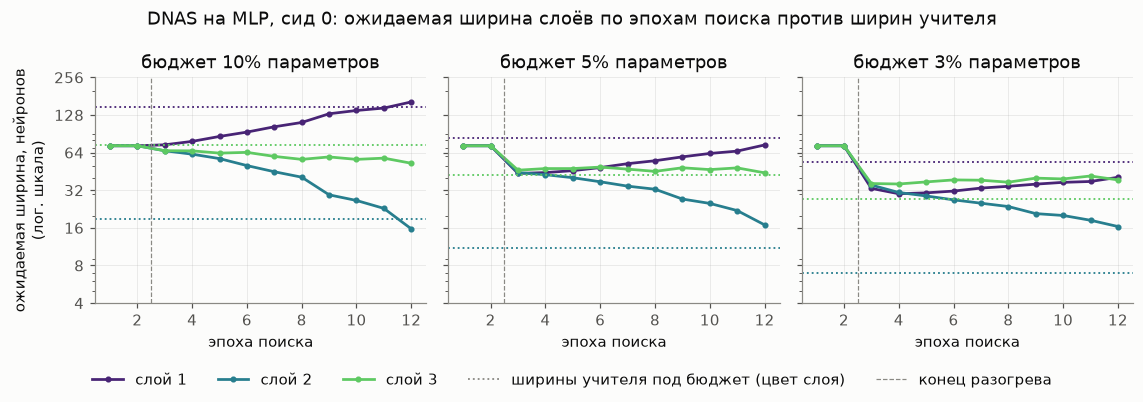

In [12]:
s0 = MLP_SEEDS[0]
warm = MLP_DNAS_KW["warmup_epochs"]
colors = plt.cm.viridis(np.linspace(0.1, 0.75, len(E3_STUDENT)))
fig, axes = plt.subplots(1, len(E3_BUDGETS), figsize=(10.5, 3.6), sharey=True)
for ax, budget in zip(axes, E3_BUDGETS):
    hist = E3_SEARCH[budget, s0]["history"]
    ep = [h["epoch"] for h in hist]
    teach = e3_widths("teacher", None, int(budget * E3_FULL))
    for l, c in enumerate(colors):
        ax.plot(ep, [h["expected_widths"][l] for h in hist], color=c, marker="o", ms=3, label=f"слой {l + 1}")
        ax.axhline(teach[l], color=c, ls=":", lw=1.2)
    ax.axvline(warm + 0.5, color=NEUTRAL, ls="--", lw=0.8)
    ax.set_yscale("log")
    ax.set_yticks([4, 8, 16, 32, 64, 128, 256], [4, 8, 16, 32, 64, 128, 256])
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlabel("эпоха поиска")
    ax.set_title(f"бюджет {budget:.0%} параметров")
axes[0].set_ylabel("ожидаемая ширина, нейронов\n(лог. шкала)")
handles = axes[0].get_legend_handles_labels()[0] + [
    plt.Line2D([], [], color=NEUTRAL, ls=":", lw=1.2), plt.Line2D([], [], color=NEUTRAL, ls="--", lw=0.8)]
fig.legend(handles, [f"слой {l + 1}" for l in range(len(E3_STUDENT))]
           + ["ширины учителя под бюджет (цвет слоя)", "конец разогрева"], loc="lower center", ncol=5)
fig.suptitle(f"DNAS на MLP, сид {s0}: ожидаемая ширина слоёв по эпохам поиска против ширин учителя")
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

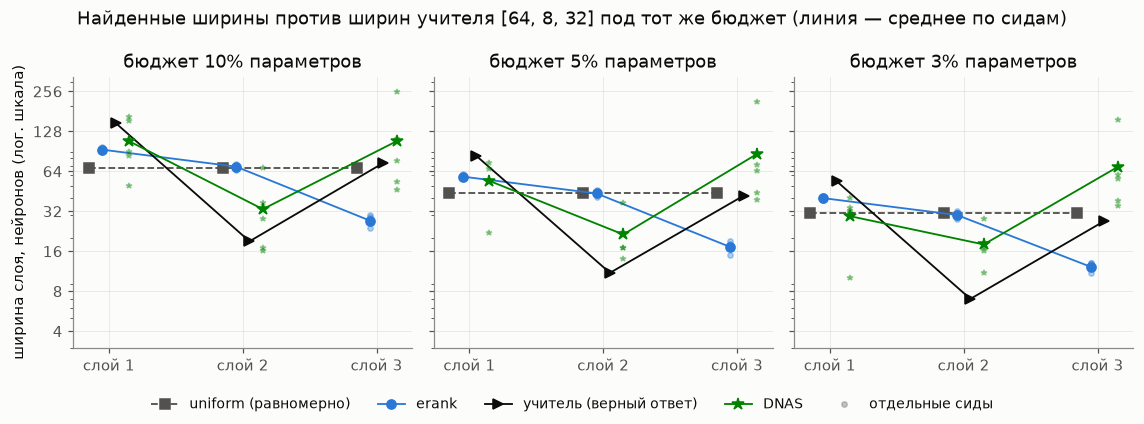

**Вывод.** Доля 2-го слоя в сумме ширин (у учителя 8%), среднее по сидам и бюджетам: uniform 33%, erank 37%, учитель 8%, DNAS 15%.

In [13]:
offsets = dict(zip(E3_METHODS, np.linspace(-0.15, 0.15, len(E3_METHODS))))
fig, axes = plt.subplots(1, len(E3_BUDGETS), figsize=(10.5, 3.8), sharey=True)
for ax, budget in zip(axes, E3_BUDGETS):
    g = E3[E3.budget == budget]
    for method in E3_METHODS:
        w = np.array(g[g.method == method].widths.tolist(), dtype=float)  # (seeds, layers)
        x = np.arange(1, w.shape[1] + 1) + offsets[method]
        ax.plot(np.tile(x, len(w)), w.ravel(), ls="none", marker=MARKERS[method], ms=3.5, color=PALETTE[method],
                alpha=0.35)  # one faint point per seed: SD bars would cross zero on a log axis
        ax.plot(x, w.mean(0), color=PALETTE[method], marker=MARKERS[method], ms=8 if method == "dnas" else 6,
                ls="--" if method == "uniform" else "-", lw=1.2, label=LABEL[method])
    ax.set_yscale("log")
    ax.set_ylim(3, 330)
    ax.set_yticks([4, 8, 16, 32, 64, 128, 256], [4, 8, 16, 32, 64, 128, 256])
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xticks([1, 2, 3], ["слой 1", "слой 2", "слой 3"])
    ax.set_title(f"бюджет {budget:.0%} параметров")
axes[0].set_ylabel("ширина слоя, нейронов (лог. шкала)")
handles, labels = axes[0].get_legend_handles_labels()
handles.append(plt.Line2D([], [], color=NEUTRAL, marker="o", ms=3.5, alpha=0.5, ls="none"))
fig.legend(handles, labels + ["отдельные сиды"], loc="lower center", ncol=5, fontsize=9)
fig.suptitle("Найденные ширины против ширин учителя [64, 8, 32] под тот же бюджет (линия — среднее по сидам)")
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()
share = {m: 100 * np.mean([w[1] / sum(w) for w in E3[E3.method == m].widths]) for m in E3_METHODS}
display(Markdown(
    f"**Вывод.** Доля 2-го слоя в сумме ширин (у учителя {100 * E1B_TEACHER[1] / sum(E1B_TEACHER):.0f}%), "
    "среднее по сидам и бюджетам: " + ", ".join(f"{SHORT[m]} {share[m]:.0f}%" for m in E3_METHODS) + "."))

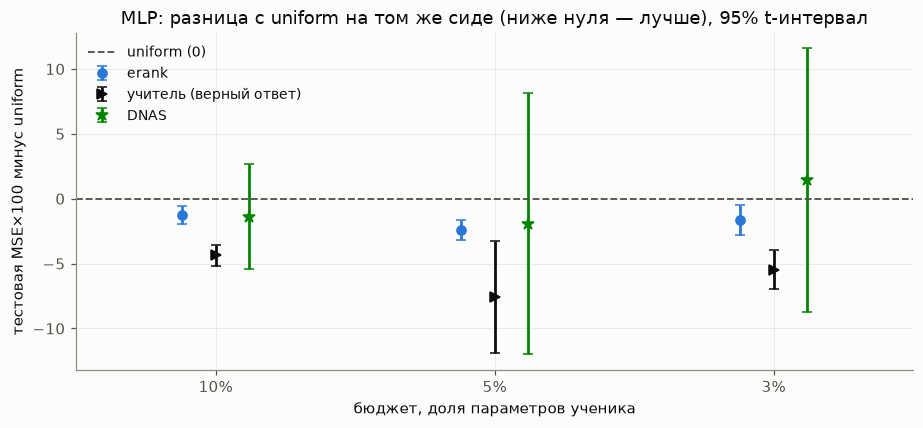

**Вывод** (MSE×100 минус uniform, меньше — лучше):
- 10%: erank −1,28 [−1,99; −0,58], n=5 — лучше; учитель (верный ответ) −4,34 [−5,15; −3,53], n=5 — лучше; DNAS −1,38 [−5,39; +2,64], n=5 — разница не отличима от нуля при n=5
- 5%: erank −2,42 [−3,19; −1,64], n=5 — лучше; учитель (верный ответ) −7,57 [−11,91; −3,22], n=5 — лучше; DNAS −1,93 [−12,00; +8,13], n=5 — разница не отличима от нуля при n=5
- 3%: erank −1,66 [−2,80; −0,52], n=5 — лучше; учитель (верный ответ) −5,46 [−6,94; −3,98], n=5 — лучше; DNAS +1,44 [−8,70; +11,58], n=5 — разница не отличима от нуля при n=5

In [14]:
A_GROUPS = [f"{b:.0%}" for b in E3_BUDGETS]
A_STATS = {}
for b, gname in zip(E3_BUDGETS, A_GROUPS):
    g = E3[E3.budget == b]
    for m in ["erank", "teacher", "dnas"]:
        A_STATS[gname, m] = paired_summary(paired_diffs(g, "test_mse", m, "uniform"))
    A_STATS[gname, "dnas-erank"] = paired_summary(paired_diffs(g, "test_mse", "dnas", "erank"))
fig, ax = plt.subplots(figsize=(8.5, 4))
plot_deltas(ax, A_GROUPS, ["erank", "teacher", "dnas"], A_STATS)
ax.set_xlabel("бюджет, доля параметров ученика")
ax.set_ylabel("тестовая MSE×100 минус uniform")
ax.set_title("MLP: разница с uniform на том же сиде (ниже нуля — лучше), 95% t-интервал")
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
lines = [f"- {g}: " + "; ".join(f"{LABEL[m]} {fmt_ci(A_STATS[g, m])} — {verdict(A_STATS[g, m], True)}"
                                  for m in ["erank", "teacher", "dnas"]) for g in A_GROUPS]
display(Markdown("**Вывод** (MSE×100 минус uniform, меньше — лучше):\n" + "\n".join(lines)))

## Часть B. ResNet-18 / CIFAR-10

Рецепт основной серии: 45 000 / 5 000 train / val (перестановка с `Generator` seed 0), официальный тест 10 000;
SGD nesterov, one-cycle lr 0.1, wd 5e-4, батч 256, 30 эпох, сдвиг до 4 пикселей и отражение, прямой проход в bf16;
оценка и erank в fp32. Ищутся только внутренние ширины 8 блоков (выход первой свёртки), ширины стадий не меняются;
нижняя граница ширины 8.

In [15]:
import warnings

DATA_ROOT = next((p for p in [Path("data"), Path("../data")]
                  if (p / "cifar-10-batches-py" / "data_batch_1").is_file()), None)
if DATA_ROOT is None:
    if not DOWNLOAD:
        raise FileNotFoundError("CIFAR-10 не найден: нужна папка cifar-10-batches-py в data/ или ../data/ "
                                "(DOWNLOAD = True разрешит скачивание)")
    from torchvision import datasets
    DATA_ROOT = Path("data")
    datasets.CIFAR10(str(DATA_ROOT), train=True, download=True)
    datasets.CIFAR10(str(DATA_ROOT), train=False, download=True)
with warnings.catch_warnings():  # numpy >= 2.4 warns inside torchvision's CIFAR unpickling
    warnings.filterwarnings("ignore", message=".*align should be passed.*")
    data = load_cifar10(str(DATA_ROOT), device="cpu", name=DATASET)
if N_TRAIN:
    data["x_train"], data["y_train"] = data["x_train"][:N_TRAIN], data["y_train"][:N_TRAIN]
if N_VAL:
    data["x_val"], data["y_val"] = data["x_val"][:N_VAL], data["y_val"][:N_VAL]
data = {k: v.to(DEVICE) for k, v in data.items()}
print({k: tuple(v.shape) for k, v in data.items()})

{'x_train': (45000, 3, 32, 32), 'y_train': (45000,), 'x_val': (5000, 3, 32, 32), 'y_val': (5000,), 'x_test': (10000, 3, 32, 32), 'y_test': (10000,)}


### B. Шаги 1–2. Базовые сети и erank внутренних слоёв

Одна полная ResNet-18 на сид. После обучения erank (λ, `erank_energy`, как в части A) всех 17 слоёв измеряется
на всей валидации (каждая позиция каждой картинки — отдельная строка, канал — признак); время измерения — часть
стоимости метода erank.

In [16]:
REF = ResNet18(num_classes=NUM_CLASSES)  # architecture template for sizes and widths (its weights are not used)
FULL = {"params": count_params(REF), "macs": count_macs(REF)}
print(f"полная ResNet-18: {FULL['params']:,} параметров, {FULL['macs']:,} MACs на картинку 32×32")


def sync() -> None:
    if DEVICE == "cuda":
        torch.cuda.synchronize()


def base_row(seed: int) -> dict:
    torch.manual_seed(seed)
    model = ResNet18(num_classes=NUM_CLASSES).to(DEVICE)
    sync()
    t_train = time.perf_counter()  # wall time with the per-epoch validation, like search_seconds of DNAS
    history = train(model, data, EPOCHS, LR, seed=seed, verbose=False)
    sync()
    train_wall = time.perf_counter() - t_train
    torch.save(model.state_dict(), ckpt(f"{ARCH}_base_s{seed}.pt"))
    layer_metrics(model, data["x_val"][:500])  # warm-up: cuDNN picks its algorithms on the first call
    sync()
    t0 = time.perf_counter()
    layers = layer_metrics(model, data["x_val"])
    sync()
    return {"seed": seed, "test_acc": evaluate(model, data["x_test"], data["y_test"])["acc"],
            "val_acc": history[-1]["val_acc"], "train_seconds": round(sum(h["seconds"] for h in history), 1),
            "train_wall_seconds": round(train_wall, 1), "erank_seconds": round(time.perf_counter() - t0, 2),
            "layers": layers, "history": history, **describe(model)}


BASES = {s: cached(f"base|{ARCH}|{DATASET}|s{s}|e{EPOCHS}", lambda: base_row(s)) for s in SEEDS}
display(pd.DataFrame([{"сид": s, "тест, %": 100 * r["test_acc"], "val, %": 100 * r["val_acc"],
                       "обучение с проверкой на val, мин": r["train_wall_seconds"] / 60,
                       "измерение erank, с": r["erank_seconds"]}
                      for s, r in BASES.items()]).round(2))
er = np.array([inner(BASES[s]["layers"], "erank_energy") for s in SEEDS])
widths_full = REF.inner_widths()
tab = pd.DataFrame({"ширина": widths_full, "erank": er.mean(0).round(1),
                    "SD": er.std(0, ddof=1).round(1) if len(SEEDS) > 1 else np.nan,
                    "erank / ширина": (er.mean(0) / widths_full).round(3)},
                   index=[f"блок {b}" for b in range(1, 9)])
display(tab)
ratio = er.mean(0) / np.array(widths_full)
display(Markdown(
    f"**Вывод.** erank / ширина внутренних слоёв — от {ratio.min():.2f} (блок {ratio.argmin() + 1}) до "
    f"{ratio.max():.2f} (блок {ratio.argmax() + 1}); по этим долям erank распределяет бюджет "
    f"(доли erank: {', '.join(f'{v:.0f}' for v in er.mean(0))})."))

полная ResNet-18: 11,173,962 параметров, 555,422,720 MACs на картинку 32×32


,сид,"тест, %","val, %","обучение с проверкой на val, мин","измерение erank, с"
0,0,92.61,93.70,2.44,7.69
1,1,92.80,93.94,2.43,7.69
2,2,93.01,93.68,2.43,7.68


,ширина,erank,SD,erank / ширина
блок 1,64,30.8,0.6,0.482
блок 2,64,33.5,1.1,0.523
блок 3,128,58.0,1.3,0.453
блок 4,128,77.9,1.7,0.609
блок 5,256,99.0,1.7,0.387
блок 6,256,137.2,0.8,0.536
блок 7,512,108.4,2.5,0.212
блок 8,512,87.1,1.3,0.170


**Вывод.** erank / ширина внутренних слоёв — от 0,17 (блок 8) до 0,61 (блок 4); по этим долям erank распределяет бюджет (доли erank: 31, 33, 58, 78, 99, 137, 108, 87).

### B. Шаг 3а. DNAS-поиск ширин

Для каждого сида и каждого бюджета — отдельный поиск на свежей полной ResNet-18 (обученная база не
используется) с настройками основной серии: 5 эпох разогрева + 15 эпох поиска, $\lambda = 1$,
шаг $\alpha$ 3e-2 (Adam) — те же, что у MLP, на CIFAR-10 не подбирались; веса — SGD с one-cycle на 20 эпох;
кандидаты: 8, 16 и каждая 1/16 исходной ширины. Сохраняются ожидаемые ширины, вся история по эпохам и время поиска
(настенное, вместе с проверкой на val после каждой эпохи).

In [17]:
def search_row(target: int, measure: str, seed: int) -> dict:
    found = search_widths(data, target, measure, seed, verbose=False, arch=ARCH, num_classes=NUM_CLASSES, **DNAS_KW)
    return {"seed": seed, "measure": measure, "target": target, **found}


CONDS = [(m, b) for m, fractions in BUDGETS.items() for b in fractions]
SEARCH = {}
kw = json.dumps(DNAS_KW, sort_keys=True)
for seed in SEEDS:
    for measure, b in CONDS:
        SEARCH[measure, b, seed] = cached(f"dnas_search|{ARCH}|{DATASET}|{measure}|{b}|s{seed}|kw={kw}",
                                          lambda: search_row(int(b * FULL[measure]), measure, seed))
display(pd.DataFrame([{"бюджет": cond_label(m, b), "сид": s,
                       "ожидаемые ширины": r["expected_widths"], "argmax": r["argmax_widths"],
                       "размер / полная": r["history"][-1]["expected_size_fraction"],
                       "цель": r["history"][-1]["target_fraction"], "поиск, с": r["search_seconds"]}
                      for (m, b, s), r in SEARCH.items()]))

,бюджет,сид,ожидаемые ширины,argmax,размер / полная,цель,"поиск, с"
0,25% параметров,0,"[44.3, 58.1, 92.7, 72.5, 58.4, 31.0, 9.3, 192.0]","[64, 60, 112, 96, 32, 8, 8, 192]",0.2514,0.25,172.2
1,25% MACs,0,"[19.5, 36.4, 45.9, 33.9, 69.2, 29.4, 9.8, 8.1]","[12, 20, 8, 8, 32, 8, 8, 8]",0.2531,0.25,172.3
2,25% параметров,1,"[44.6, 20.2, 111.4, 47.9, 40.0, 39.3, 96.8, 135.6]","[48, 12, 112, 24, 16, 48, 64, 128]",0.2506,0.25,172.4
3,25% MACs,1,"[34.7, 10.3, 67.0, 22.4, 27.7, 32.9, 10.4, 121.7]","[52, 8, 56, 8, 16, 8, 8, 128]",0.2501,0.25,172.2
4,25% параметров,2,"[37.2, 62.1, 42.8, 72.0, 169.2, 171.7, 42.6, 64.1]","[40, 64, 16, 72, 224, 96, 32, 64]",0.2507,0.25,172.3
5,25% MACs,2,"[18.4, 26.5, 21.0, 62.3, 52.4, 60.6, 13.5, 8.1]","[8, 20, 8, 72, 32, 96, 8, 8]",0.2506,0.25,172.2


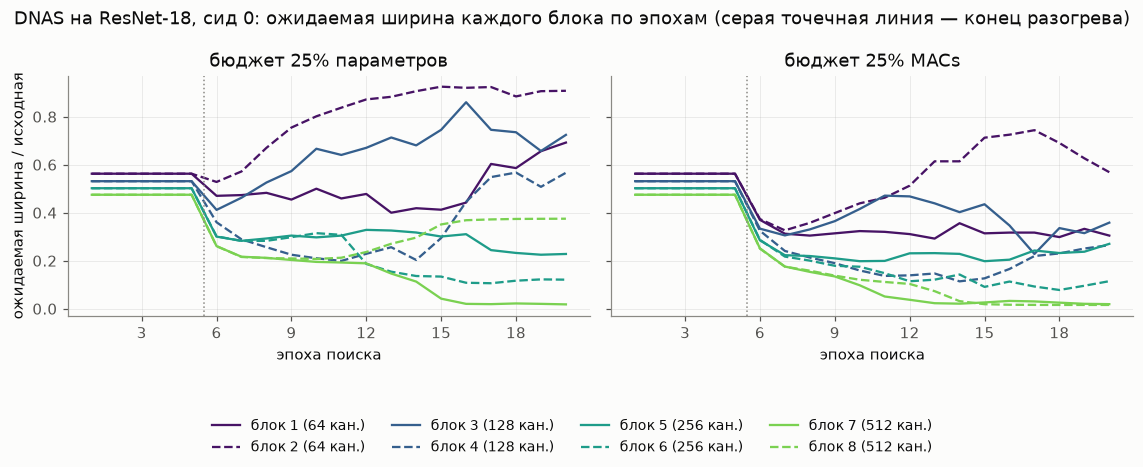

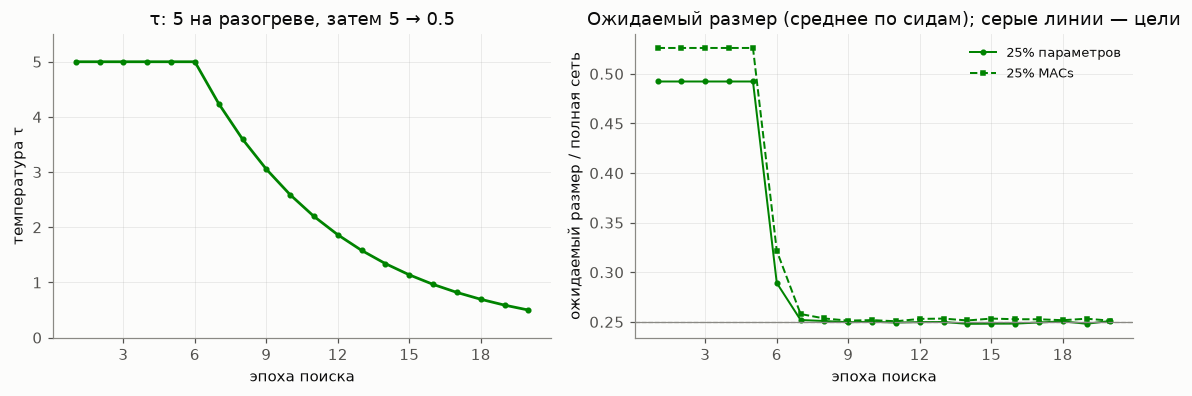

**Вывод.** За последнюю эпоху поиска ожидаемая ширина блока меняется в среднем на 1,9% исходной ширины (максимум 6,7%): поиск к концу не застыл, ответ зависит от последних эпох. Ожидаемый размер в конце — 1,00…1,01 от цели; затем ширины масштабируются под бюджет.

In [18]:
s0 = SEEDS[0]
stage_colors = plt.cm.viridis(np.linspace(0.05, 0.8, 4))  # one colour per stage; dashed = 2nd block of the stage
NR = (len(CONDS) + 1) // 2
fig, axes = plt.subplots(NR, 2, figsize=(10.5, 3.3 * NR + 0.9), sharex=True, sharey=True, squeeze=False)
for ax, (m, b) in zip(axes.flat, CONDS):
    hist = SEARCH[m, b, s0]["history"]
    ep = [h["epoch"] for h in hist]
    for k in range(len(widths_full)):
        ax.plot(ep, [h["expected_widths"][k] / widths_full[k] for h in hist], color=stage_colors[k // 2],
                ls="-" if k % 2 == 0 else "--", lw=1.5, label=f"блок {k + 1} ({widths_full[k]} кан.)")
    ax.axvline(DNAS_KW["warmup_epochs"] + 0.5, color=NEUTRAL, ls=":", lw=1)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(f"бюджет {cond_label(m, b)}")
for ax in axes[-1]:
    ax.set_xlabel("эпоха поиска")
for ax in axes[:, 0]:
    ax.set_ylabel("ожидаемая ширина / исходная")
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=9)
fig.suptitle(f"DNAS на ResNet-18, сид {s0}: ожидаемая ширина каждого блока по эпохам "
             "(серая точечная линия — конец разогрева)")
fig.tight_layout(rect=(0, 0.18 / NR, 1, 1))
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.7))
hist = SEARCH[CONDS[0] + (s0,)]["history"]
ep = [h["epoch"] for h in hist]
axes[0].plot(ep, [h["tau"] for h in hist], color=PALETTE["dnas"], marker="o", ms=3)
axes[0].set_ylim(0, 5.5)
axes[0].set_xlabel("эпоха поиска")
axes[0].set_ylabel("температура τ")
axes[0].set_title("τ: 5 на разогреве, затем 5 → 0.5")
for (m, b), ls, mk in zip(CONDS, ["-", "--", "-.", ":"], ["o", "s", "^", "v"]):
    frac = np.array([[h["expected_size_fraction"] for h in SEARCH[m, b, s]["history"]] for s in SEEDS]).mean(0)
    axes[1].plot(ep, frac, color=PALETTE["dnas"], ls=ls, marker=mk, ms=3, lw=1.3, label=cond_label(m, b))
    axes[1].axhline(b, color=NEUTRAL, ls=ls, lw=0.8)
axes[1].set_xlabel("эпоха поиска")
axes[1].set_ylabel("ожидаемый размер / полная сеть")
axes[1].set_title("Ожидаемый размер (среднее по сидам); серые линии — цели")
axes[1].legend(fontsize=8.5)
for ax in axes:
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.tight_layout()
plt.show()

last_change = [np.abs(np.subtract(r["history"][-1]["expected_widths"], r["history"][-2]["expected_widths"]))
               / np.array(widths_full) for r in SEARCH.values() if len(r["history"]) > 1]
moved = 100 * np.mean(last_change) if last_change else float("nan")
worst = 100 * np.max(last_change) if last_change else float("nan")
gap = [r["history"][-1]["expected_size_fraction"] / r["history"][-1]["target_fraction"] for r in SEARCH.values()]
display(Markdown(
    f"**Вывод.** За последнюю эпоху поиска ожидаемая ширина блока меняется в среднем на {moved:.1f}% исходной "
    f"ширины (максимум {worst:.1f}%): " + ("поиск к концу не застыл, ответ зависит от последних эпох. "
                                           if worst > 5 else "к концу поиска ширины почти не меняются. ")
    + f"Ожидаемый размер в конце — {min(gap):.2f}…{max(gap):.2f} от цели; затем ширины масштабируются под бюджет."))

### B. Шаг 3б. Обучение с нуля: uniform, erank, DNAS

Ширины каждого метода приводятся к бюджету `fit_budget` (масштаб растёт на 1%, пока сеть помещается; округление
Python `round`; не уже 8 и не шире исходной); сеть обучается с нуля полным рецептом на том же сиде.
uniform — доли ∝ исходным ширинам, erank — ∝ `erank_energy` базы этого сида, DNAS — ∝ ожидаемым ширинам поиска.

In [19]:
def scratch_row(widths: list[int], seed: int) -> dict:
    torch.manual_seed(seed)
    model = ResNet18(widths, NUM_CLASSES).to(DEVICE)
    history = train(model, data, EPOCHS, LR, seed=seed, verbose=False)
    return {"seed": seed, "test_acc": evaluate(model, data["x_test"], data["y_test"])["acc"],
            "val_acc": history[-1]["val_acc"],
            "train_acc": evaluate(model, data["x_train"][:5000], data["y_train"][:5000])["acc"],
            "train_seconds": round(sum(h["seconds"] for h in history), 1), **describe(model)}


rows = []
for seed in SEEDS:
    for measure, b in CONDS:
        for method in METHODS:
            widths = propose_widths(method, REF, BASES[seed]["layers"], int(b * FULL[measure]), measure,
                                    SEARCH[measure, b, seed])
            r = cached(f"scratch|{ARCH}|{DATASET}|w={wid(widths)}|s{seed}|e{EPOCHS}", lambda: scratch_row(widths, seed))
            rows.append({"seed": seed, "measure": measure, "budget": b, "method": method, "widths": widths,
                         **{k: r[k] for k in ("params", "macs", "test_acc", "val_acc", "train_acc", "train_seconds")}})
R18 = pd.DataFrame(rows)
agg = (R18.assign(acc=100 * R18.test_acc).groupby(["measure", "budget", "method"], sort=False)
       .agg(acc=("acc", "mean"), sd=("acc", "std"), params=("params", "mean"), macs=("macs", "mean")))
agg["тест, % (± SD)"] = [f"{a:.2f} ± {s:.2f}" if s == s else f"{a:.2f}" for a, s in zip(agg.acc, agg.sd)]
agg["параметры, млн"] = (agg.params / 1e6).round(3)
agg["MACs, млн"] = (agg.macs / 1e6).round(1)
agg.index = pd.MultiIndex.from_tuples([(cond_label(m, b), SHORT[meth]) for m, b, meth in agg.index],
                                      names=["бюджет", "метод"])
display(agg[["тест, % (± SD)", "параметры, млн", "MACs, млн"]])
print(f"Ширины блоков, сид {SEEDS[0]}:")
w0 = R18[R18.seed == SEEDS[0]].set_index(["measure", "budget", "method"]).widths
display(pd.DataFrame({SHORT[meth]: [w0[m, b, meth] for m, b in CONDS] for meth in METHODS},
                     index=pd.Index([cond_label(m, b) for m, b in CONDS], name="бюджет")))

тест, % (± SD)  параметры, млн  MACs, млн
бюджет         метод                                            
25% параметров uniform   91.93 ± 0.12           2.776      136.6
               erank     92.52 ± 0.08           2.775      219.1
               DNAS      92.33 ± 0.08           2.775      252.4
25% MACs       uniform   91.95 ± 0.16           2.801      137.4
               erank     91.85 ± 0.22           1.781      138.0
               DNAS      91.56 ± 0.19           1.262      138.2

Ширины блоков, сид 0:


,uniform,erank,DNAS
бюджет,,,
25% параметров,"[15, 15, 30, 30, 60, 60, 121, 121]","[27, 31, 52, 69, 89, 123, 98, 78]","[44, 57, 92, 72, 58, 31, 9, 190]"
25% MACs,"[15, 15, 30, 30, 61, 61, 122, 122]","[17, 19, 32, 42, 55, 76, 60, 48]","[19, 36, 45, 33, 68, 29, 10, 8]"


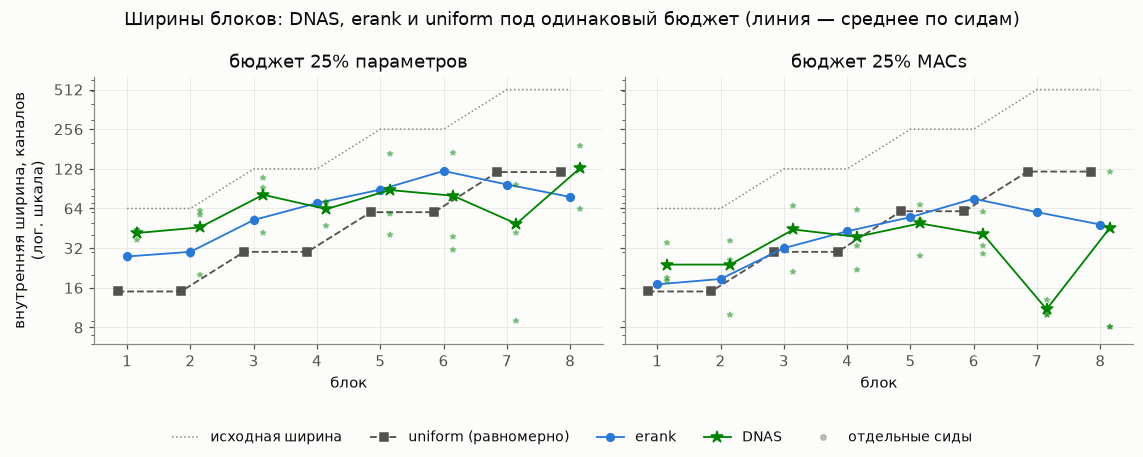

**Вывод.** Доля ширин блоков 7–8 (стадия 512 каналов) в сумме ширин: 25% параметров — uniform 54%, erank 31%, DNAS 32%; 25% MACs — uniform 54%, erank 31%, DNAS 19%.

In [20]:
offsets = dict(zip(METHODS, [-0.15, 0.0, 0.15]))
NR = (len(CONDS) + 1) // 2
fig, axes = plt.subplots(NR, 2, figsize=(10.5, 3.2 * NR + 0.9), sharex=True, sharey=True, squeeze=False)
blocks = np.arange(1, len(widths_full) + 1)
for ax, (m, b) in zip(axes.flat, CONDS):
    ax.plot(blocks, widths_full, color=NEUTRAL, ls=":", lw=1, label="исходная ширина")
    g = R18[(R18.measure == m) & (R18.budget == b)]
    for method in METHODS:
        w = np.array(g[g.method == method].widths.tolist(), dtype=float)  # (seeds, blocks)
        x = blocks + offsets[method]
        ax.plot(np.tile(x, len(w)), w.ravel(), ls="none", marker=MARKERS[method], ms=3.5, color=PALETTE[method],
                alpha=0.35)  # one faint point per seed: SD bars would cross zero on a log axis
        ax.plot(x, w.mean(0), color=PALETTE[method], marker=MARKERS[method], ms=8 if method == "dnas" else 5,
                ls="--" if method == "uniform" else "-", lw=1.2, label=LABEL[method])
    ax.set_yscale("log")
    ax.set_ylim(6, 640)
    ax.set_yticks([8, 16, 32, 64, 128, 256, 512], [8, 16, 32, 64, 128, 256, 512])
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_title(f"бюджет {cond_label(m, b)}")
for ax in axes[-1]:
    ax.set_xlabel("блок")
    ax.set_xticks(blocks)
for ax in axes[:, 0]:
    ax.set_ylabel("внутренняя ширина, каналов\n(лог. шкала)")
handles, labels = axes[0, 0].get_legend_handles_labels()
handles.append(plt.Line2D([], [], color=NEUTRAL, marker="o", ms=3.5, alpha=0.5, ls="none"))
fig.legend(handles, labels + ["отдельные сиды"], loc="lower center", ncol=5, fontsize=9)
fig.suptitle("Ширины блоков: DNAS, erank и uniform под одинаковый бюджет (линия — среднее по сидам)")
fig.tight_layout(rect=(0, 0.1 / NR, 1, 1))
plt.show()
late = {(m, b, meth): 100 * np.mean([sum(w[6:]) / sum(w) for w in
                                     R18[(R18.measure == m) & (R18.budget == b) & (R18.method == meth)].widths])
        for m, b in CONDS for meth in METHODS}
display(Markdown("**Вывод.** Доля ширин блоков 7–8 (стадия 512 каналов) в сумме ширин: " + "; ".join(
    f"{cond_label(m, b)} — " + ", ".join(f"{SHORT[meth]} {late[m, b, meth]:.0f}%" for meth in METHODS)
    for m, b in CONDS) + "."))

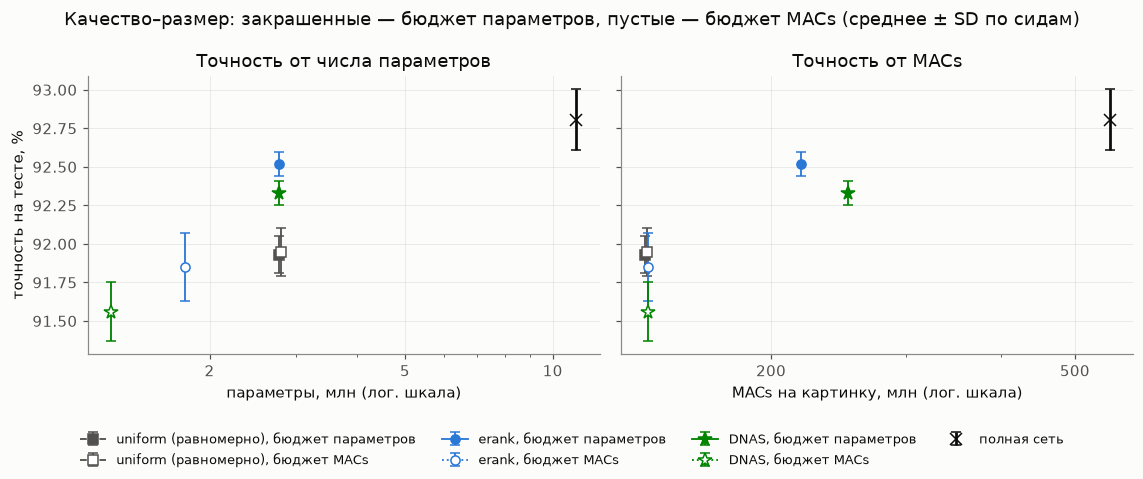

**Вывод.** При бюджете параметров методы тратят разное число MACs (к uniform): 25% — erank ×1,60, DNAS ×1,85. Поэтому точность сравнивается и при бюджете MACs.

In [21]:
full_acc = 100 * np.array([BASES[s]["test_acc"] for s in SEEDS])
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3), sharey=True)
for ax, xkey, xlabel in zip(axes, ["params", "macs"], ["параметры, млн (лог. шкала)", "MACs на картинку, млн (лог. шкала)"]):
    for method in METHODS:
        for measure, filled in [("params", True), ("macs", False)]:
            g = R18[(R18.method == method) & (R18.measure == measure)].groupby("budget")
            acc = 100 * g.test_acc.mean()
            ax.errorbar(g[xkey].mean() / 1e6, acc, yerr=(100 * g.test_acc.std()).fillna(0), color=PALETTE[method],
                        marker=MARKERS[method], ms=9 if method == "dnas" else 6, capsize=3,
                        mfc=PALETTE[method] if filled else "white", lw=1.2,
                        ls="--" if method == "uniform" else ("-" if filled else ":"),
                        label=f"{LABEL[method]}, бюджет {'параметров' if filled else 'MACs'}")
    ax.errorbar(FULL[xkey] / 1e6, full_acc.mean(), yerr=full_acc.std(ddof=1) if len(full_acc) > 1 else 0,
                color="#0b0b0b", marker=MARKERS["full"], ms=8, capsize=3, ls="none", label="полная сеть")
    ax.set_xscale("log")
    plain_log_ticks(ax, "x")
    ax.set_xlabel(xlabel)
axes[0].set_ylabel("точность на тесте, %")
axes[0].set_title("Точность от числа параметров")
axes[1].set_title("Точность от MACs")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=8.5)
fig.suptitle("Качество–размер: закрашенные — бюджет параметров, пустые — бюджет MACs (среднее ± SD по сидам)")
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()
mac_ratio = {(b, meth): R18[(R18.measure == "params") & (R18.budget == b) & (R18.method == meth)].macs.mean()
             / R18[(R18.measure == "params") & (R18.budget == b) & (R18.method == "uniform")].macs.mean()
             for b in BUDGETS["params"] for meth in METHODS}
display(Markdown("**Вывод.** При бюджете параметров методы тратят разное число MACs (к uniform): " + "; ".join(
    f"{b:.0%} — erank ×{mac_ratio[b, 'erank']:.2f}, DNAS ×{mac_ratio[b, 'dnas']:.2f}" for b in BUDGETS["params"])
    + ". Поэтому точность сравнивается и при бюджете MACs."))

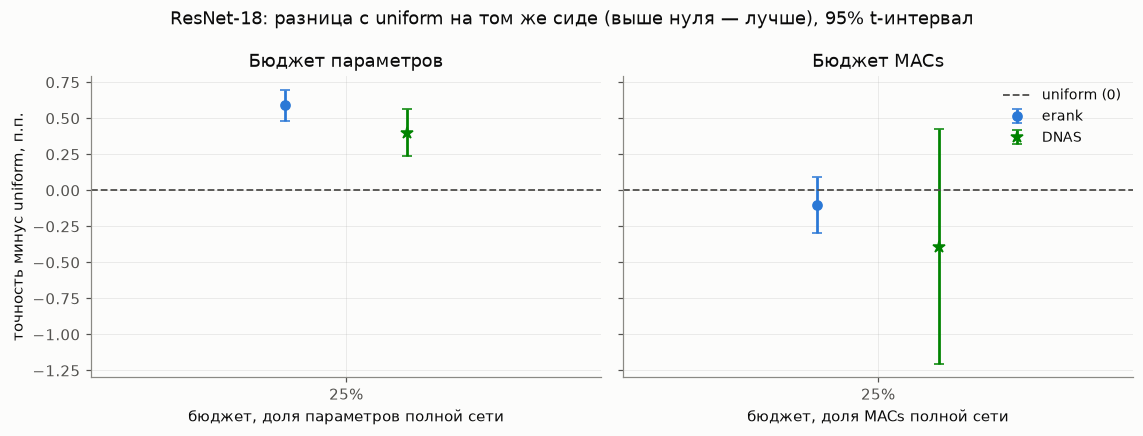

**Вывод** (точность минус uniform, п.п.):
- 25% параметров: erank +0,59 [+0,48; +0,70], n=3 — лучше; DNAS +0,40 [+0,24; +0,56], n=3 — лучше
- 25% MACs: erank −0,10 [−0,29; +0,09], n=3 — разница не отличима от нуля при n=3; DNAS −0,39 [−1,20; +0,42], n=3 — разница не отличима от нуля при n=3

Впереди uniform по точности и с большим числом MACs, чем у uniform: erank при 25% параметров — +0,59 п.п. при ×1,60 MACs; DNAS при 25% параметров — +0,40 п.п. при ×1,85 MACs. Часть этой разницы может объясняться дополнительными вычислениями (см. бюджет MACs).

In [22]:
B_STATS = {}
for m, b in CONDS:
    g = R18[(R18.measure == m) & (R18.budget == b)]
    for meth in ["erank", "dnas"]:
        B_STATS[(m, b), meth] = paired_summary(paired_diffs(g, "test_acc", meth, "uniform"))
    B_STATS[(m, b), "dnas-erank"] = paired_summary(paired_diffs(g, "test_acc", "dnas", "erank"))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4), sharey=True)
for ax, m in zip(axes, BUDGETS):
    groups = [f"{b:.0%}" for b in BUDGETS[m]]
    plot_deltas(ax, groups, ["erank", "dnas"], {(f"{b:.0%}", meth): B_STATS[(m, b), meth]
                                                for b in BUDGETS[m] for meth in ["erank", "dnas"]})
    ax.set_xlabel(f"бюджет, доля {RES_OF[m]} полной сети")
    ax.set_title(f"Бюджет {RES_OF[m]}")
axes[0].set_ylabel("точность минус uniform, п.п.")
axes[1].legend(fontsize=9)
fig.suptitle("ResNet-18: разница с uniform на том же сиде (выше нуля — лучше), 95% t-интервал")
fig.tight_layout()
plt.show()
lines = [f"- {cond_label(m, b)}: erank {fmt_ci(B_STATS[(m, b), 'erank'])} — {verdict(B_STATS[(m, b), 'erank'])}; "
         f"DNAS {fmt_ci(B_STATS[(m, b), 'dnas'])} — {verdict(B_STATS[(m, b), 'dnas'])}" for m, b in CONDS]
extra_macs = [f"{SHORT[meth]} при {cond_label('params', b)} — {B_STATS[('params', b), meth]['mean_pp']:+.2f} п.п. "
              f"при ×{mac_ratio[b, meth]:.2f} MACs"
              for b in BUDGETS["params"] for meth in ["erank", "dnas"]
              if (B_STATS[("params", b), meth]["mean_pp"] or 0) > 0 and mac_ratio[b, meth] > 1.05]
if extra_macs:  # only where a method is ahead of uniform AND spends more MACs
    lines.append("\nВпереди uniform по точности и с большим числом MACs, чем у uniform: " + "; ".join(extra_macs)
                 + ". Часть этой разницы может объясняться дополнительными вычислениями (см. бюджет MACs).")
display(Markdown("**Вывод** (точность минус uniform, п.п.):\n" + "\n".join(lines)))

### B. Стоимость выбора ширин

erank требует одну обученную полную сеть (общую для всех бюджетов; она же — готовая полная модель) и одно
измерение erank; DNAS — отдельный поиск на каждый бюджет. Время — из этого прогона, настенное: обучение базы и
поиск DNAS считаются одинаково, вместе с проверкой на val после каждой эпохи.

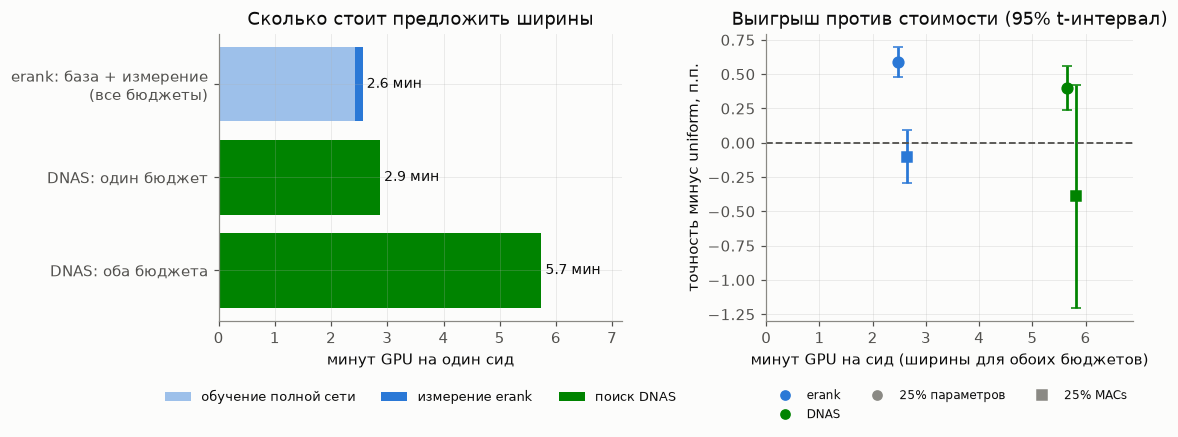

**Вывод.** Один DNAS-поиск — в среднем 2,9 мин GPU (1,2× обучения полной сети), на 2 бюджета — 5,7 мин на сид. erank: обучение базы 2,4 мин (одна на все бюджеты) + измерение 7,7 с.

In [23]:
base_min = np.mean([BASES[s]["train_wall_seconds"] for s in SEEDS]) / 60
meas_min = np.mean([BASES[s]["erank_seconds"] for s in SEEDS]) / 60
dnas_min = {c: np.mean([SEARCH[c + (s,)]["search_seconds"] for s in SEEDS]) / 60 for c in CONDS}
one = np.mean(list(dnas_min.values()))
total = {"erank": base_min + meas_min, "dnas": sum(dnas_min.values())}  # widths for all budgets, one seed
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw={"width_ratios": [1.1, 1]})
ax = axes[0]
names = ["erank: база + измерение\n(все бюджеты)", "DNAS: один бюджет", ("DNAS: оба бюджета" if len(CONDS) == 2 else f"DNAS: все {len(CONDS)} бюджета")]
ax.barh(0, base_min, color=PALETTE["erank"], alpha=0.45, label="обучение полной сети")
ax.barh(0, meas_min, left=base_min, color=PALETTE["erank"], label="измерение erank")
ax.barh(1, one, color=PALETTE["dnas"], label="поиск DNAS")
ax.barh(2, sum(dnas_min.values()), color=PALETTE["dnas"])
for y, v in enumerate([base_min + meas_min, one, sum(dnas_min.values())]):
    ax.text(v, y, f" {v:.1f} мин", va="center", color="#0b0b0b", fontsize=9)
ax.set_yticks(range(3), names)
ax.invert_yaxis()
ax.set_xlim(0, 1.25 * max(base_min + meas_min, sum(dnas_min.values())))
ax.set_xlabel("минут GPU на один сид")
ax.set_title("Сколько стоит предложить ширины")
ax.legend(fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
ax = axes[1]
xmax = max(total.values())
cond_markers = list(zip(CONDS, ["o", "s", "^", "v"]))  # one marker per budget; legend handles = labels
for i, ((m, b), mk) in enumerate(cond_markers):
    shift = (i - (len(CONDS) - 1) / 2) * 0.03 * xmax  # budgets side by side, so the intervals do not overlap
    for meth in ["erank", "dnas"]:
        s = B_STATS[(m, b), meth]
        ci = s["ci95_pp"] or [s["mean_pp"], s["mean_pp"]]
        ax.errorbar(total[meth] + shift, s["mean_pp"], yerr=[[s["mean_pp"] - ci[0]], [ci[1] - s["mean_pp"]]],
                    fmt=mk, color=PALETTE[meth], capsize=3, ms=7)
ax.axhline(0, color=PALETTE["uniform"], ls="--", lw=1.2)
ax.set_xlim(0, 1.2 * xmax)
ax.set_xlabel("минут GPU на сид (ширины для " + ("обоих бюджетов)" if len(CONDS) == 2 else f"всех {len(CONDS)} бюджетов)"))
ax.set_ylabel("точность минус uniform, п.п.")
ax.set_title("Выигрыш против стоимости (95% t-интервал)")
handles = [plt.Line2D([], [], color=PALETTE[k], marker="o", ls="none") for k in ["erank", "dnas"]]
handles += [plt.Line2D([], [], color=NEUTRAL, marker=mk, ls="none") for _, mk in cond_markers]
ax.legend(handles, ["erank", "DNAS"] + [cond_label(m, b) for (m, b), _ in cond_markers], fontsize=8, ncol=3,
          loc="upper center", bbox_to_anchor=(0.5, -0.2))
fig.tight_layout()
plt.show()
display(Markdown(
    f"**Вывод.** Один DNAS-поиск — в среднем {one:.1f} мин GPU ({one / base_min:.1f}× обучения полной сети), "
    f"на {len(CONDS)} бюджета — {sum(dnas_min.values()):.1f} мин на сид. erank: обучение базы {base_min:.1f} мин "
    f"(одна на все бюджеты) + измерение {60 * meas_min:.1f} с."))

### Что здесь не повторяется

Этот файл сравнивает только правила выбора ширин (erank, DNAS, uniform) при обучении с нуля; остальные пункты
задания — в `01_mlp`, `02_resnet18`, `03_vit`.
- **Шаг 2:** сравнение вариантов erank и других спектральных мер с измеренной сжимаемостью слоя, erank по эпохам
  обучения и контроль без обучения. Здесь используется только `erank_energy` в конце обучения.
- **Бейзлайны прунинга:** случайные ширины, L1-норма фильтров (Li et al., 2017), Network Slimming / γ BN, Taylor,
  HRank, низкоранговая SVD. Здесь erank сравнивается только с uniform и DNAS.
- **Шаги 4–5:** дообучение вырезанной сети и итерации «erank → ширины → обучение». Найденная DNAS архитектура, как
  и в основной серии, проверяется только обучением с нуля.
- **MACs и время инференса MLP:** в MLP каждый вес даёт одно умножение-сложение на пример, поэтому MACs почти
  равны числу параметров (не считаются только смещения и BN), и отдельный бюджет MACs ничего не меняет; время
  инференса MLP измеряется в `01_mlp`.

## Размер, MACs и время инференса

Сети сида 0 из Шага 3б и полная ResNet-18 (точность — у базы сида 0; время меряется на сетях со случайными весами,
от весов оно не зависит). Один замер — медиана 30 повторов после 5 прогревов. Сначала GPU (bf16, батч 512): один
общий прогревочный проход по всем сетям, затем все сети подряд, у каждой — медиана трёх замеров; между замерами
на GPU нет пауз на счёт CPU. Затем CPU (fp32, 4 потока): батч 32 и батч 1 (100 повторов). Время меряется заново
при каждом запуске ячейки (около 20 с) и не кэшируется: замер на занятом процессоре не должен сохраниться в результатах.

2026-11-08 09:35:51  latency of 7 nets (measured anew on every run, not cached)


2026-11-08 09:36:08  latency done (17 s)


,метод,бюджет,"тест, %","параметры, млн","MACs, млн","CPU батч 32, мс","CPU батч 1, мс","GPU батч 512, мс"
0,полная сеть,—,92.61,11.17,555.42,60.74,6.09,13.93
1,uniform,25% параметров,91.79,2.78,136.61,19.23,2.65,7.73
2,erank,25% параметров,92.43,2.77,218.49,29.38,2.92,9.27
3,DNAS,25% параметров,92.25,2.78,261.36,34.51,3.02,10.62
4,uniform,25% MACs,91.79,2.80,137.38,19.24,2.70,7.75
5,erank,25% MACs,91.65,1.78,137.75,22.60,2.66,7.97
6,DNAS,25% MACs,91.65,0.91,138.20,23.21,2.39,8.52


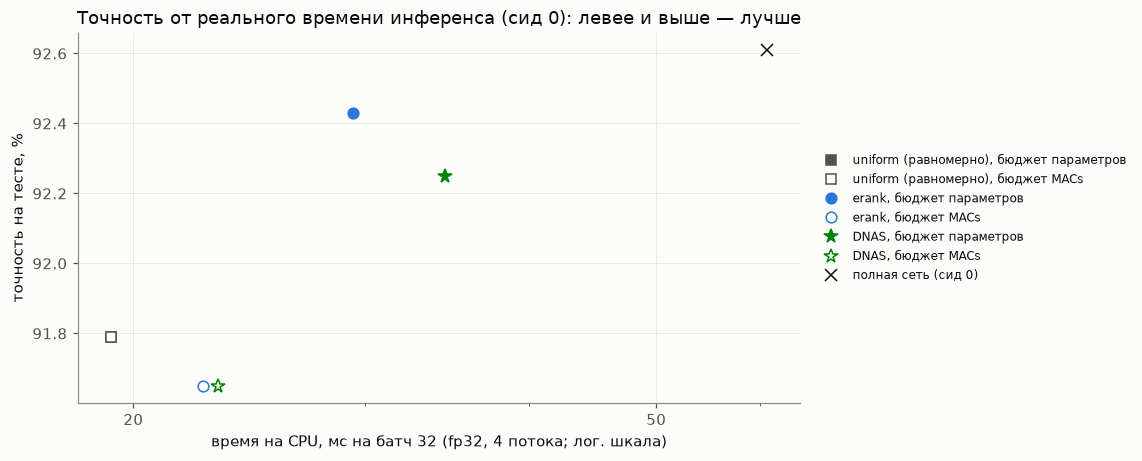

**Вывод.** Спирмен (MACs, время) по 7 сетям: CPU батч 32 1,00, CPU батч 1 0,75, GPU батч 512 1,00; Спирмен (параметры, время CPU батч 32) 0,29: время на CPU точнее следует за MACs, чем за числом параметров.

In [24]:
GPU_MACS_TOL, GPU_TIME_RATIO = 0.01, 1.2  # check of the GPU timing: MACs within 1% should not differ by > 20% in time


def gpu_noisy_pairs(df, macs_tol: float, time_ratio: float) -> list[tuple[int, int]]:
    """Row positions (i, j) of nets whose MACs differ by less than macs_tol but whose GPU times differ by more than
    time_ratio times: then the GPU timing does not resolve these nets and its Spearman is unreliable."""
    if not df.gpu_ms_batch512.notna().all():
        return []
    macs, gpu = df.macs.tolist(), df.gpu_ms_batch512.tolist()
    return [(i, j) for i in range(len(df)) for j in range(i + 1, len(df))
            if abs(macs[i] - macs[j]) < macs_tol * min(macs[i], macs[j])
            and max(gpu[i], gpu[j]) > time_ratio * min(gpu[i], gpu[j])]


nets = [{"method": "full", "measure": "—", "budget": 1.0, "widths": widths_full,
         "test_acc": BASES[SEEDS[0]]["test_acc"]}]  # the base of the same seed as the other nets
nets += R18[R18.seed == SEEDS[0]][["method", "measure", "budget", "widths", "test_acc"]].to_dict("records")
log(f"latency of {len(nets)} nets (measured anew on every run, not cached)")
t_lat = time.perf_counter()
models = {key: ResNet18(list(key), NUM_CLASSES) for key in dict.fromkeys(tuple(n["widths"]) for n in nets)}
measured = {key: {"params": count_params(m), "macs": count_macs(m), "gpu_ms_batch512": None}
            for key, m in models.items()}  # identical widths are timed once
if DEVICE == "cuda":  # pass 1: all GPU timings back to back, no CPU work in between
    for m in models.values():
        m.to(DEVICE)
    for m in models.values():  # one untimed pass over every net first (cuDNN algorithm choice, GPU clocks)
        latency_ms(m, DEVICE, 512, 1)
    for key, m in models.items():
        measured[key]["gpu_ms_batch512"] = float(np.median([latency_ms(m, DEVICE, 512, LAT_REPEATS)
                                                            for _ in range(LAT_GPU_CALLS)]))
    for m in models.values():
        m.cpu()
    torch.cuda.empty_cache()
threads = torch.get_num_threads()
torch.set_num_threads(LAT_THREADS)
try:  # pass 2: CPU
    for key, m in models.items():
        measured[key]["cpu_ms_batch32"] = latency_ms(m, "cpu", 32, LAT_REPEATS)
        measured[key]["cpu_ms_batch1"] = latency_ms(m, "cpu", 1, LAT_REPEATS_B1)
finally:
    torch.set_num_threads(threads)
lat = [{**n, **measured[tuple(n["widths"])]} for n in nets]
log(f"latency done ({time.perf_counter() - t_lat:.0f} s)")
LAT_DF = pd.DataFrame(lat)
LAT_NAMES = {"cpu_ms_batch32": "CPU батч 32, мс", "cpu_ms_batch1": "CPU батч 1, мс", "gpu_ms_batch512": "GPU батч 512, мс"}
show = pd.DataFrame({"метод": LAT_DF.method.map(SHORT),
                     "бюджет": [cond_label(m, b) if m in RES_OF else "—" for m, b in zip(LAT_DF.measure, LAT_DF.budget)],
                     "тест, %": 100 * LAT_DF.test_acc, "параметры, млн": LAT_DF.params / 1e6,
                     "MACs, млн": LAT_DF.macs / 1e6, **{v: LAT_DF[k] for k, v in LAT_NAMES.items()}})
display(show.round(2))
fig, ax = plt.subplots(figsize=(10.5, 4.3))
for method in METHODS:
    for measure, filled in [("params", True), ("macs", False)]:
        g = LAT_DF[(LAT_DF.method == method) & (LAT_DF.measure == measure)]
        ax.plot(g.cpu_ms_batch32, 100 * g.test_acc, color=PALETTE[method], marker=MARKERS[method], ls="none",
                ms=9 if method == "dnas" else 7, mfc=PALETTE[method] if filled else "white",
                label=f"{LABEL[method]}, бюджет {'параметров' if filled else 'MACs'}")
f = LAT_DF[LAT_DF.method == "full"]
ax.plot(f.cpu_ms_batch32, 100 * f.test_acc, color="#0b0b0b", marker=MARKERS["full"], ms=8, ls="none",
        label=f"полная сеть (сид {SEEDS[0]})")
ax.set_xscale("log")
plain_log_ticks(ax, "x")
ax.set_xlabel("время на CPU, мс на батч 32 (fp32, 4 потока; лог. шкала)")
ax.set_ylabel("точность на тесте, %")
ax.set_title(f"Точность от реального времени инференса (сид {SEEDS[0]}): левее и выше — лучше")
ax.legend(fontsize=8, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()
rho = {k: spearman(LAT_DF.macs, LAT_DF[k]) for k in LAT_NAMES if LAT_DF[k].notna().all()}
rho_p = spearman(LAT_DF.params, LAT_DF.cpu_ms_batch32)


def net_name(i: int) -> str:
    return show["метод"][i] + ("" if show["бюджет"][i] == "—" else f" ({show['бюджет'][i]})")


def ratio(col: str, i: int, j: int) -> float:
    a, b = LAT_DF[col][i], LAT_DF[col][j]
    return max(a, b) / min(a, b)


noisy = gpu_noisy_pairs(LAT_DF, GPU_MACS_TOL, GPU_TIME_RATIO)
gpu_caveat = (
    f" Оговорка про GPU: почти равные по MACs сети (разница меньше {GPU_MACS_TOL:.0%}) расходятся по времени на GPU "
    f"больше чем на {GPU_TIME_RATIO - 1:.0%} — " + "; ".join(
        f"{net_name(i)} и {net_name(j)}: MACs различаются на {100 * (ratio('macs', i, j) - 1):.1f}%, время на GPU — "
        f"в {ratio('gpu_ms_batch512', i, j):.2f} раза" for i, j in noisy)
    + "; при таком размере сетей замер на GPU шумный, и ρ для GPU по этому замеру ненадёжен." if noisy else "")
display(Markdown(
    f"**Вывод.** Спирмен (MACs, время) по {len(LAT_DF)} сетям: "
    + ", ".join(f"{LAT_NAMES[k].replace(', мс', '')} {v:.2f}" for k, v in rho.items())
    + f"; Спирмен (параметры, время CPU батч 32) {rho_p:.2f}: время на CPU "
    + ("точнее следует за MACs, чем за числом параметров." if rho["cpu_ms_batch32"] > rho_p
       else "следует за MACs не точнее, чем за числом параметров.") + gpu_caveat))

## Итог

Разница с uniform на том же сиде и бюджете: среднее, 95% t-интервал, n сидов. ResNet-18 — точность на тесте, п.п.
(больше — лучше); MLP — тестовая MSE×100 (меньше — лучше). «DNAS − erank» — прямое сравнение двух способов выбора
ширин на одном сиде.

In [25]:
rows_b = [{"бюджет": cond_label(m, b),
           "uniform, %": f"{100 * R18[(R18.measure == m) & (R18.budget == b) & (R18.method == 'uniform')].test_acc.mean():.2f}",
           "erank − uniform": fmt_ci(B_STATS[(m, b), "erank"]), "DNAS − uniform": fmt_ci(B_STATS[(m, b), "dnas"]),
           "DNAS − erank": fmt_ci(B_STATS[(m, b), "dnas-erank"]),
           "поиск DNAS, мин": round(dnas_min[m, b], 1)} for m, b in CONDS]
print("ResNet-18 / CIFAR-10, точность на тесте (п.п.):")
display(pd.DataFrame(rows_b))
rows_a = [{"бюджет": f"{g} параметров", "uniform, MSE×100": f"{100 * E3[(E3.budget == b) & (E3.method == 'uniform')].test_mse.mean():.2f}",
           "erank − uniform": fmt_ci(A_STATS[g, "erank"]), "учитель − uniform": fmt_ci(A_STATS[g, "teacher"]),
           "DNAS − uniform": fmt_ci(A_STATS[g, "dnas"]), "DNAS − erank": fmt_ci(A_STATS[g, "dnas-erank"])}
          for b, g in zip(E3_BUDGETS, A_GROUPS)]
print("MLP учитель → ученик, тестовая MSE×100 (меньше — лучше):")
display(pd.DataFrame(rows_a))


def tally(stats: dict, keys: list, method: str, lower: bool = False) -> str:
    words = [verdict(stats[k, method], lower) for k in keys]
    better, worse = words.count("лучше"), words.count("хуже")
    undefined = sum(w.startswith("интервал не определён") for w in words)
    parts = [f"лучше в {better} из {len(words)}", f"хуже в {worse}"]
    if len(words) - better - worse - undefined:
        parts.append(f"не отличимо от нуля в {len(words) - better - worse - undefined}")
    if undefined:
        parts.append(f"интервал не определён (n=1) в {undefined}")
    return ", ".join(parts)


b_keys, a_keys = list(CONDS), A_GROUPS
display(Markdown("\n".join([
    f"**ResNet-18 / CIFAR-10** (n = {len(SEEDS)}, {len(CONDS)} бюджета): erank против uniform — "
    f"{tally(B_STATS, b_keys, 'erank')}; DNAS против uniform — {tally(B_STATS, b_keys, 'dnas')}; "
    f"DNAS против erank — {tally(B_STATS, b_keys, 'dnas-erank')} (значения по бюджетам — в таблице). "
    f"Цена: один поиск DNAS ≈ {one:.1f} мин GPU на бюджет против {base_min:.1f} мин на базу + {60 * meas_min:.0f} с "
    "на erank для всех бюджетов.",
    "",
    f"**MLP учитель → ученик** (n = {len(MLP_SEEDS)}, {len(a_keys)} бюджета): erank против uniform — "
    f"{tally(A_STATS, a_keys, 'erank', True)}; DNAS против uniform — {tally(A_STATS, a_keys, 'dnas', True)}; "
    f"учитель (оракул) против uniform — {tally(A_STATS, a_keys, 'teacher', True)}; "
    f"DNAS против erank — {tally(A_STATS, a_keys, 'dnas-erank', True)}.",
    "",
    "Интервал, накрывающий ноль, не означает равенства методов: при таком n разница просто не отличима от нуля.",
])))

ResNet-18 / CIFAR-10, точность на тесте (п.п.):


,бюджет,"uniform, %",erank − uniform,DNAS − uniform,DNAS − erank,"поиск DNAS, мин"
0,25% параметров,91.93,"+0.59 [+0.48; +0.70], n=3","+0.40 [+0.24; +0.56], n=3","-0.19 [-0.28; -0.10], n=3",2.9
1,25% MACs,91.95,"-0.10 [-0.29; +0.09], n=3","-0.39 [-1.20; +0.42], n=3","-0.29 [-1.29; +0.71], n=3",2.9


MLP учитель → ученик, тестовая MSE×100 (меньше — лучше):


,бюджет,"uniform, MSE×100",erank − uniform,учитель − uniform,DNAS − uniform,DNAS − erank
0,10% параметров,6.79,"-1.28 [-1.99; -0.58], n=5","-4.34 [-5.15; -3.53], n=5","-1.38 [-5.39; +2.64], n=5","-0.09 [-4.05; +3.87], n=5"
1,5% параметров,13.79,"-2.42 [-3.19; -1.64], n=5","-7.57 [-11.91; -3.22], n=5","-1.93 [-12.00; +8.13], n=5","+0.48 [-10.29; +11.26], n=5"
2,3% параметров,19.59,"-1.66 [-2.80; -0.52], n=5","-5.46 [-6.94; -3.98], n=5","+1.44 [-8.70; +11.58], n=5","+3.10 [-6.03; +12.23], n=5"


**ResNet-18 / CIFAR-10** (n = 3, 2 бюджета): erank против uniform — лучше в 1 из 2, хуже в 0, не отличимо от нуля в 1; DNAS против uniform — лучше в 1 из 2, хуже в 0, не отличимо от нуля в 1; DNAS против erank — лучше в 0 из 2, хуже в 1, не отличимо от нуля в 1 (значения по бюджетам — в таблице). Цена: один поиск DNAS ≈ 2,9 мин GPU на бюджет против 2,4 мин на базу + 8 с на erank для всех бюджетов.

**MLP учитель → ученик** (n = 5, 3 бюджета): erank против uniform — лучше в 3 из 3, хуже в 0; DNAS против uniform — лучше в 0 из 3, хуже в 0, не отличимо от нуля в 3; учитель (оракул) против uniform — лучше в 3 из 3, хуже в 0; DNAS против erank — лучше в 0 из 3, хуже в 0, не отличимо от нуля в 3.

Интервал, накрывающий ноль, не означает равенства методов: при таком n разница просто не отличима от нуля.

### Сравнение с основной серией

Числа ниже взяты из основной серии (те же рецепты и протокол; не вычислены в этом файле).

- **ResNet-18 / CIFAR-10, n = 3, точность минус uniform, п.п.:** бюджет параметров 25% — erank +0.59, DNAS +0.40;
  10% — erank +0.62, DNAS +1.25. Бюджет MACs 25% — erank −0.10, DNAS −0.39; 10% — erank −0.16, DNAS −0.66.
  uniform: 91.93 / 90.46 (параметры 25% / 10%), 91.95 / 90.48 (MACs). При бюджете параметров 10% DNAS тратит
  ≈ 166 млн MACs против 60 млн у uniform и 84 млн у erank.
- **Стоимость:** один DNAS-поиск ≈ 172 с на бюджет и сид (настенное время, с проверкой на val после каждой эпохи);
  erank — обучение базы ≈ 142 с чистого времени эпох, без проверок на val (одна база на все бюджеты) + измерение
  7.2 с. Поиск к концу не сходится полностью: ширины ещё меняются на последних эпохах.
- **MLP учитель → ученик, n = 5, тестовая MSE×100 минус uniform (меньше — лучше):** 10% — erank −1.28,
  учитель −4.34, DNAS −1.38; 5% — −2.42 / −7.57 / −1.93; 3% — −1.66 / −5.46 / +1.44. uniform: 6.79 / 13.79 / 19.59.
  Настройки DNAS для MLP выбирались перебором по валидации на сиде 0 этой же задачи, что слегка играет в пользу DNAS.